# v5 — Frozen DINOv3 ViT-L/16 pada data mentah resmi BDC

**Tujuan.** Menghasilkan `submission_SD2026040000412.csv` untuk klasifikasi tiga kelas BDC Satria Data 2026 hanya dari piksel citra resmi dan label train resmi. Backbone dibekukan secara ketat; seluruh parameter yang dapat dilatih hanya berada pada probe supervised yang kecil.

**Kontrak fail-closed.** Notebook ini hanya menerima signature train mentah `0_Recyclable=9999`, `1_Electronic=3961`, `2_Organic=12567` (total 26.527) dan tepat 1.458 baris test sesuai urutan template. Varian relabel, root dataset ambigu, cache tidak kompatibel, fold/checkpoint tidak lengkap, citra rusak, template salah, dan prediksi non-integer akan menghentikan eksekusi.

**Kepatuhan kompetisi.** File test belum dienumerasi sampai resep head dan kebijakan TTA selesai dipilih hanya dari validasi train. Tidak ada pseudo-label, adaptasi test, kalibrasi yang di-fit pada test, fitur metadata, label eksternal, maupun unggah Kaggle otomatis.

## Sintesis bukti dan keputusan

Bukti repository diperlakukan sebagai bukti engineering, bukan kode yang disalin tanpa evaluasi:

- `baseline-v1-convnext.ipynb`: mempertahankan pembacaan RGB yang aman terhadap EXIF, fold stratified deterministik, laporan macro-F1, dan pemeriksaan submission; fallback fold tidak lengkap serta substitusi exact-match train/test ditolak.
- `experiment-v2-maxvit.ipynb`: mempertahankan membership ensemble yang dapat diaudit; pencarian checkpoint nonrekursif dan fallback diam-diam ditolak.
- `v3-convnext.ipynb`: mempertahankan resolusi root berbasis signature isi, akuntansi OOF penuh, assertion checkpoint rekursif, dan konfigurasi satu sumber. Kontrak count khusus relabel sengaja diganti dengan signature mentah resmi.
- `v4-freeze-convnext.ipynb`: menunjukkan freeze ConvNeXtV2 lemah pada data ini. Hal itu bukan bukti langsung melawan frozen DINOv3 karena DINOv3 memang dilatih sebagai representasi frozen yang transferable.
- Notebook referensi DINO: mempertahankan model Hugging Face dan gagasan `CLS + mean(patch)` yang benar. Register token dikeluarkan memakai config yang dimuat; logika face/subject/metadata, kredensial tertanam, dan asumsi VRAM 48 GB ditolak.
- Template klasifikasi/segmentasi lain: mempertahankan filter parameter optimizer dan pemeriksaan artifact yang relevan; CRNN, decoder, tumpukan focal loss, subject grouping, dan full fine-tuning yang tidak relevan ditolak.

Temuan paper diterapkan secara konservatif:

- Benchmark sampah (`2602.10500v2`) mendukung transfer learning, perhatian pada imbalance, dan verifikasi manfaat resolusi lebih tinggi; dipilih satu resolusi 384 px, bukan ensemble resolusi.
- Studi TTA (`2604.09697v1`) memperingatkan bahwa TTA dapat merugikan; hanya view original dan horizontal flip yang dicache, lalu OOF menentukan pemakaiannya.
- FracMix (`2606.25784v1`) memberi peningkatan robustness yang kecil namun memerlukan aset sintetik eksternal dan machinery tambahan, sehingga ditolak.
- Studi optical explainability (`2505.16513v1`) dan review industrial waste memperingatkan dominasi background, logo, bentuk, clutter, dan domain shift; karena itu notebook menghasilkan diagnostik confidence dan error.
- DECMCV (`2503.02241v1`) dan WaRP (`s00521-023-08864-4`) memperkuat manfaat representasi pretrained, tetapi clustering dan dual-stream mereka tidak membenarkan komponen tambahan di sini.
- GTTA (`2507.01347v2`) melakukan test-time adaptation dan tidak diperbolehkan. Model soup (`2603.02181v1`) menambah kompleksitas lifecycle untuk potensi gain kecil; averaging seed probe yang murah dipilih. Paper Heliyon `main` berbasis ECOC/custom-CNN bukan bukti kompetitif bagi hipotesis frozen foundation model ini.

Ini hipotesis baru, bukan jaminan gain leaderboard. Skor DINOv3 eksternal yang dilaporkan dalam `CONTEXT.md` hanya dipakai sebagai bukti pendukung; skor itu tidak direproduksi atau divalidasi di sini.

In [1]:
# DINOv3 support is present in released Transformers versions >= 4.56.
%pip install -q "transformers>=4.56,<5"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 78.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 27.1 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [2]:
import gc
import hashlib
import json
import os
import random
import time
from copy import deepcopy
from pathlib import Path

os.environ['TOKENIZERS_PARALLELISM'] = 'false'

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image, ImageFile, ImageOps
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
)
from sklearn.model_selection import StratifiedKFold
from torch.utils.data import DataLoader, Dataset, TensorDataset
from torchvision.transforms import InterpolationMode, v2
from tqdm.auto import tqdm
import transformers
from transformers import AutoImageProcessor, AutoModel
from huggingface_hub import model_info

print('torch:', torch.__version__)
print('transformers:', transformers.__version__)


torch: 2.10.0+cu128
transformers: 4.57.6


## Konfigurasi terpusat

`screen` mengekstrak fitur train deterministik yang sama, membandingkan resep hanya pada fold 0, dan menampilkan nama resep valid yang dapat dikunci. Skor ini adalah **bukti seleksi resep**, bukan estimasi OOF unbiased. Setelah meninjau hasil screen, pengguna mengisi `FINAL_RECIPE_NAME` secara manual. `full` tidak mengulang pencarian resep; mode ini memerlukan resep terkunci, sedikitnya dua GPU CUDA, lima fold, dan dua seed probe. `DEBUG_LIMIT=0` wajib untuk menghasilkan submission.

Backbone frozen dihitung dalam FP32 untuk stabilitas numerik pada T4. Cache tetap memakai FP16 secara default hanya setelah tensor pooled FP32 lolos pemeriksaan shape, finite, dan rentang FP16; compute dtype dan storage dtype sengaja terpisah. Bila FP32 kehabisan VRAM, turunkan `FEATURE_BATCH_SIZE` manual dari 4 ke 2 lalu lanjutkan shard yang belum selesai—tidak ada retry atau perubahan dtype otomatis.

Rentang versi `transformers` sengaja tetap longgar untuk smoke run Kaggle pertama. Setelah satu run Kaggle benar-benar berhasil, pin versi runtime yang tercetak untuk reproduksibilitas final; tidak ada versi yang diklaim terverifikasi secara lokal.

In [3]:
RUN_MODE = 'full'                 # 'screen' or 'full'
DEBUG_LIMIT = 0                 # 0 = all rows; otherwise >= 15, balanced across fold/class
FINAL_RECIPE_NAME = 'mlp_concat_weighted_ce'         # setelah screen: isi salah satu nama dari VALID_RECIPE_NAMES
SEED = 42
N_FOLDS = 5
NUM_CLASSES = 3
RECIPE_SELECTION_FOLDS = (0,)
ASSESSMENT_FOLDS = (1, 2, 3, 4)

MODEL_ID = 'facebook/dinov3-vitl16-pretrain-lvd1689m'
MODEL_REVISION = None            # resolved Hub commit is recorded after loading
IMAGE_SIZE = 384                 # divisible by the documented patch size 16
FEATURE_VIEWS = ('orig', 'hflip')
FEATURE_BATCH_SIZE = 4           # total DataParallel batch; 2 images per T4
FEATURE_WORKERS = 4
FEATURE_SHARD_SIZE = 512          # satu shard kecil cukup untuk resume tanpa framework tambahan
BACKBONE_COMPUTE_DTYPE = torch.float32
BACKBONE_COMPUTE_DTYPE_NAME = 'float32'
FEATURE_STORAGE_DTYPE = torch.float16
FEATURE_STORAGE_DTYPE_NAME = 'float16'
ATTENTION_IMPLEMENTATION = 'sdpa'
HEAD_BATCH_SIZE = 512
PREDICT_BATCH_SIZE = 1024
SCREEN_EPOCHS = 15
FULL_EPOCHS = 15
EARLY_STOPPING_PATIENCE = 5
HEAD_SEEDS_FULL = (42, 314)
TTA_MIN_MACRO_F1_GAIN = 0.0002
LARGE_IMAGE_MP_THRESHOLD = 8_000_000
LARGE_IMAGE_MAX_SOURCE_SIDE = 4096
SAFE_COPY_MAX_SIDE = 1024
SAFE_COPY_JPEG_QUALITY = 95
PIL_MAX_IMAGE_PIXELS = 200_000_000

CLASS_DIR_TO_LABEL = {
    '0_Recyclable': 0,
    '1_Electronic': 1,
    '2_Organic': 2,
}
CLASS_NAMES = ('Recyclable', 'Electronic', 'Organic')
EXPECTED_RAW_COUNTS = {0: 9999, 1: 3961, 2: 12567}
EXPECTED_TRAIN_ROWS = 26527
EXPECTED_TEST_ROWS = 1458
ALLOWED_IMAGE_SUFFIXES = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
RECIPES = [
    {'name': 'linear_cls_ce', 'pooling': 'cls', 'head': 'linear', 'loss': 'ce', 'simplicity': 0},
    {'name': 'linear_mean_ce', 'pooling': 'mean', 'head': 'linear', 'loss': 'ce', 'simplicity': 0},
    {'name': 'linear_concat_ce', 'pooling': 'concat', 'head': 'linear', 'loss': 'ce', 'simplicity': 1},
    {'name': 'mlp_concat_ce', 'pooling': 'concat', 'head': 'mlp', 'loss': 'ce', 'simplicity': 2},
    {'name': 'mlp_concat_weighted_ce', 'pooling': 'concat', 'head': 'mlp', 'loss': 'weighted_ce', 'simplicity': 3},
]
VALID_RECIPE_NAMES = tuple(recipe['name'] for recipe in RECIPES)

assert RUN_MODE in {'screen', 'full'}
assert DEBUG_LIMIT == 0 or DEBUG_LIMIT >= N_FOLDS * NUM_CLASSES
assert RECIPE_SELECTION_FOLDS == (0,)
assert set(RECIPE_SELECTION_FOLDS).isdisjoint(ASSESSMENT_FOLDS)
assert set(RECIPE_SELECTION_FOLDS + ASSESSMENT_FOLDS) == set(range(N_FOLDS))
assert BACKBONE_COMPUTE_DTYPE == torch.float32
assert BACKBONE_COMPUTE_DTYPE_NAME == 'float32'
assert FEATURE_STORAGE_DTYPE in {torch.float16, torch.float32}
assert FEATURE_STORAGE_DTYPE_NAME == str(FEATURE_STORAGE_DTYPE).replace('torch.', '')
if FINAL_RECIPE_NAME is not None and FINAL_RECIPE_NAME not in VALID_RECIPE_NAMES:
    raise ValueError(f'FINAL_RECIPE_NAME tidak valid: {FINAL_RECIPE_NAME!r}. Pilih dari {VALID_RECIPE_NAMES}.')
if RUN_MODE == 'full' and FINAL_RECIPE_NAME is None:
    raise ValueError(
        'Full mode memerlukan FINAL_RECIPE_NAME yang dikunci manual setelah screen. '
        f'Pilihan valid: {VALID_RECIPE_NAMES}'
    )
FULL_RUN = RUN_MODE == 'full' and DEBUG_LIMIT == 0
if RUN_MODE == 'full' and DEBUG_LIMIT:
    raise ValueError('RUN_MODE="full" requires DEBUG_LIMIT=0; debug runs cannot submit.')

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True, warn_only=True)
torch.set_float32_matmul_precision('high')
Image.MAX_IMAGE_PIXELS = PIL_MAX_IMAGE_PIXELS  # finite guard; gambar besar dipra-resize secara aman
ImageFile.LOAD_TRUNCATED_IMAGES = False


In [4]:
def has_dataset_signature(root):
    return (
        root.is_dir()
        and (root / 'train').is_dir()
        and (root / 'test').is_dir()
        and (root / 'submission.csv').is_file()
    )

def resolve_data_root():
    known = [Path.cwd() / 'data', Path('/kaggle/working/data')]
    matches = {p.resolve() for p in known if has_dataset_signature(p)}
    for base in (Path('/kaggle/input'), Path.cwd()):
        if not base.exists():
            continue
        for template in base.rglob('submission.csv'):
            if has_dataset_signature(template.parent):
                matches.add(template.parent.resolve())
    if len(matches) != 1:
        found = '\n'.join(f'  - {p}' for p in sorted(matches, key=str)) or '  (none)'
        raise RuntimeError(
            'Expected exactly one dataset root with train/, test/, and submission.csv; '
            f'found {len(matches)}:\n{found}'
        )
    return matches.pop()

DATA_ROOT = resolve_data_root()
TRAIN_DIR = DATA_ROOT / 'train'
TEST_DIR = DATA_ROOT / 'test'
TEMPLATE_PATH = DATA_ROOT / 'submission.csv'

KAGGLE_WORKING = Path('/kaggle/working')
if not KAGGLE_WORKING.is_dir():
    raise RuntimeError('This notebook targets a Kaggle runtime with /kaggle/working available.')
ARTIFACT_DIR = KAGGLE_WORKING / 'v5_dinov3_frozen_raw'
CACHE_DIR = ARTIFACT_DIR / 'feature_cache'
CHECKPOINT_ROOT = ARTIFACT_DIR / 'checkpoints'
for directory in (ARTIFACT_DIR, CACHE_DIR, CHECKPOINT_ROOT):
    directory.mkdir(parents=True, exist_ok=True)

print('Resolved dataset root:', DATA_ROOT)
print('Artifacts:', ARTIFACT_DIR)


Resolved dataset root: /kaggle/input/bdc-2026-waste-classification-dataset
Artifacts: /kaggle/working/v5_dinov3_frozen_raw


In [5]:
def index_raw_train(train_dir):
    rows = []
    observed_counts = {}
    actual_class_dirs = {p.name for p in train_dir.iterdir() if p.is_dir()}
    if actual_class_dirs != set(CLASS_DIR_TO_LABEL):
        raise RuntimeError(
            f'Unexpected train class directories: {sorted(actual_class_dirs)}; '
            f'expected {sorted(CLASS_DIR_TO_LABEL)}'
        )

    for class_dir_name, label in CLASS_DIR_TO_LABEL.items():
        class_dir = train_dir / class_dir_name
        entries = sorted(class_dir.iterdir(), key=lambda p: p.name)
        invalid = [p.name for p in entries if not p.is_file() or p.suffix.lower() not in ALLOWED_IMAGE_SUFFIXES]
        if invalid:
            raise RuntimeError(f'Unsupported or nested entries in {class_dir}: {invalid[:10]}')
        observed_counts[label] = len(entries)
        for path in entries:
            relative_path = path.relative_to(train_dir).as_posix()
            rows.append({
                'image_id': relative_path,
                'relative_path': relative_path,
                'class_name': CLASS_NAMES[label],
                'path': str(path.resolve()),
                'label': label,
            })

    if observed_counts != EXPECTED_RAW_COUNTS:
        raise RuntimeError(
            'This is not the official raw train set. '
            f'Observed {observed_counts}; expected {EXPECTED_RAW_COUNTS}. '
            'Do not run v5 on a relabeled or augmented train tree.'
        )
    frame = pd.DataFrame(rows).sort_values('image_id').reset_index(drop=True)
    assert len(frame) == EXPECTED_TRAIN_ROWS
    assert frame['image_id'].is_unique and frame['relative_path'].is_unique
    assert set(frame['label'].unique()) == set(range(NUM_CLASSES))
    assert frame['path'].map(lambda value: Path(value).is_file()).all()
    return frame

train_df = index_raw_train(TRAIN_DIR)
train_df['fold'] = -1
splitter = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
for fold, (_, valid_index) in enumerate(splitter.split(train_df, train_df['label'])):
    train_df.loc[valid_index, 'fold'] = fold

assert (train_df['fold'] >= 0).all()
fold_class_counts = train_df.groupby(['fold', 'label']).size().unstack(fill_value=0)
assert fold_class_counts.shape == (N_FOLDS, NUM_CLASSES)
assert (fold_class_counts > 0).all().all()
train_df[['image_id', 'relative_path', 'class_name', 'label', 'fold']].to_csv(
    ARTIFACT_DIR / 'fold_assignments.csv', index=False
)

if DEBUG_LIMIT:
    per_group = max(1, DEBUG_LIMIT // (N_FOLDS * NUM_CLASSES))
    debug_parts = []
    for (fold, label), group in train_df.groupby(['fold', 'label'], sort=True):
        debug_parts.append(group.sample(n=min(per_group, len(group)), random_state=SEED + fold * 10 + label))
    run_df = pd.concat(debug_parts).sort_values('image_id').reset_index(drop=True)
else:
    run_df = train_df.copy().reset_index(drop=True)

print('Raw class counts:', train_df['label'].value_counts().sort_index().to_dict())
print('Fold/class counts:\n', fold_class_counts)
print('Rows active in this run:', len(run_df))


Raw class counts: {0: 9999, 1: 3961, 2: 12567}
Fold/class counts:
 label     0    1     2
fold                  
0      2000  792  2514
1      2000  792  2514
2      2000  792  2513
3      2000  792  2513
4      1999  793  2513
Rows active in this run: 26527


image safety train:   0%|          | 0/26527 [00:00<?, ?it/s]

Image safety train: 233 large, 233 dibuat, 0 dipakai ulang. Dimensi tidak digunakan sebagai fitur.


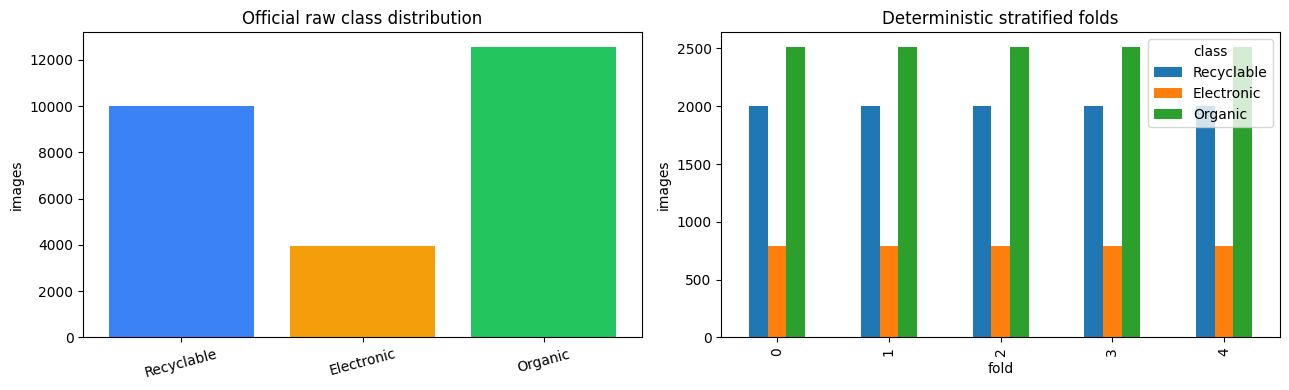

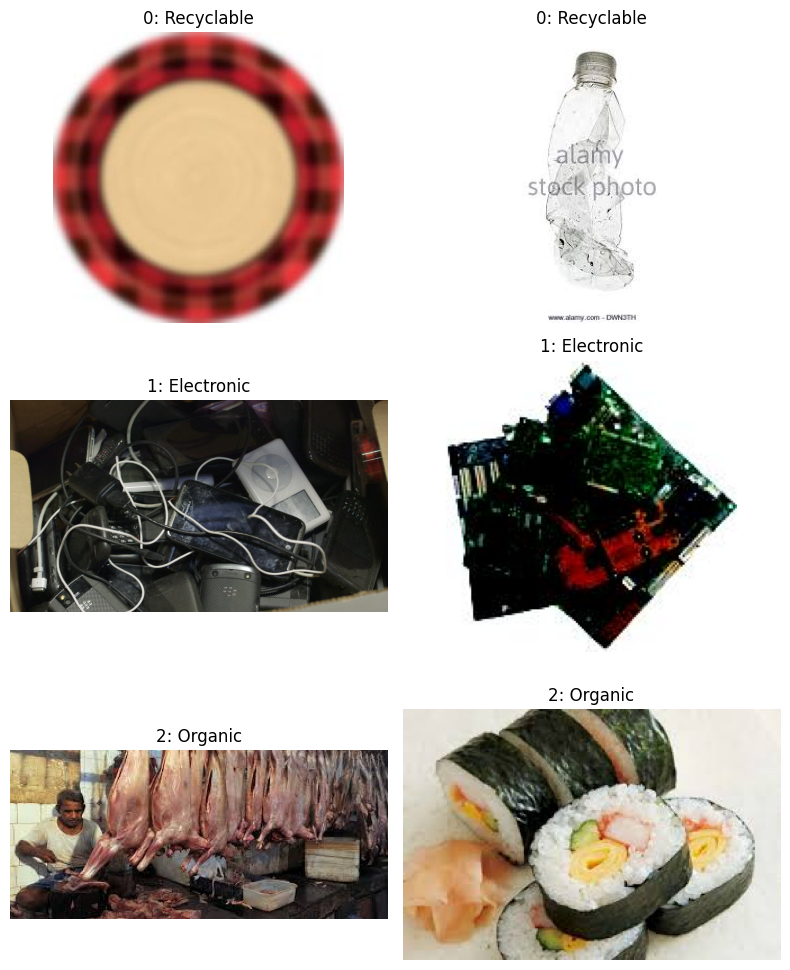

In [6]:
def inspect_image_dimensions(path):
    try:
        with Image.open(path) as image:
            width, height = image.size
        if width <= 0 or height <= 0:
            raise ValueError(f'invalid dimensions {width}x{height}')
        return int(width), int(height)
    except Exception as exc:
        raise RuntimeError(f'Gagal membaca header/dimensi citra: {path}') from exc

def safe_copy_is_valid(path):
    try:
        with Image.open(path) as image:
            width, height = image.size
            mode = image.mode
            image.verify()
        return width > 0 and height > 0 and max(width, height) <= SAFE_COPY_MAX_SIDE and mode == 'RGB'
    except Exception:
        return False

def write_safe_copy(source_path, destination_path):
    destination_path.parent.mkdir(parents=True, exist_ok=True)
    temporary_path = destination_path.with_name(
        f'{destination_path.stem}.tmp{destination_path.suffix.lower()}'
    )
    format_by_suffix = {
        '.jpg': 'JPEG', '.jpeg': 'JPEG', '.png': 'PNG',
        '.bmp': 'BMP', '.webp': 'WEBP',
    }
    image_format = format_by_suffix.get(destination_path.suffix.lower())
    if image_format is None:
        raise RuntimeError(f'Format safe-copy tidak didukung: {destination_path.suffix}')
    try:
        with Image.open(source_path) as image:
            image.draft('RGB', (SAFE_COPY_MAX_SIDE, SAFE_COPY_MAX_SIDE))
            image = ImageOps.exif_transpose(image).convert('RGB')
            image.thumbnail((SAFE_COPY_MAX_SIDE, SAFE_COPY_MAX_SIDE), Image.Resampling.LANCZOS)
            save_kwargs = {'quality': SAFE_COPY_JPEG_QUALITY} if image_format in {'JPEG', 'WEBP'} else {}
            image.save(temporary_path, format=image_format, **save_kwargs)
        os.replace(temporary_path, destination_path)
    except Exception as exc:
        raise RuntimeError(
            f'Gagal membuat safe-copy {destination_path} dari {source_path}'
        ) from exc
    if not safe_copy_is_valid(destination_path):
        raise RuntimeError(f'Safe-copy tidak valid setelah ditulis: {destination_path}')

def prepare_safe_image_paths(frame, split):
    if split not in {'train', 'test'}:
        raise ValueError(f'Split safe-copy tidak dikenal: {split}')
    prepared = frame.copy()
    original_ids = prepared['image_id'].astype(str).tolist()
    prepared['source_path'] = prepared['path'].astype(str)
    safe_root = (
        ARTIFACT_DIR / 'safe_images'
        / f'max_side_{SAFE_COPY_MAX_SIDE}_quality_{SAFE_COPY_JPEG_QUALITY}' / split
    )
    records = []
    created = reused = 0
    for index, row in tqdm(prepared.iterrows(), total=len(prepared), desc=f'image safety {split}'):
        source_path = Path(row['source_path'])
        if not source_path.is_file():
            raise RuntimeError(f'File sumber tidak ditemukan: {source_path}')
        width, height = inspect_image_dimensions(source_path)
        needs_safe_copy = (
            width * height >= LARGE_IMAGE_MP_THRESHOLD
            or max(width, height) > LARGE_IMAGE_MAX_SOURCE_SIDE
        )
        effective_path = source_path
        if needs_safe_copy:
            destination_path = safe_root / Path(row['relative_path'])
            if safe_copy_is_valid(destination_path):
                reused += 1
            else:
                write_safe_copy(source_path, destination_path)
                created += 1
            if not destination_path.is_file() or not safe_copy_is_valid(destination_path):
                raise RuntimeError(f'Safe-copy wajib tidak tersedia/valid: {destination_path}')
            effective_path = destination_path
        prepared.at[index, 'path'] = str(effective_path)
        records.append({
            'image_id': str(row['image_id']),
            'source_path': str(source_path),
            'effective_path': str(effective_path),
            'source_width': width,
            'source_height': height,
            'used_safe_copy': bool(needs_safe_copy),
        })
    if prepared['image_id'].astype(str).tolist() != original_ids:
        raise RuntimeError('Pre-resize safety mengubah urutan image_id.')
    missing = [path for path in prepared['path'] if not Path(path).is_file()]
    if missing:
        raise RuntimeError(f'{len(missing)} effective image path hilang; contoh: {missing[:3]}')
    mapping_path = ARTIFACT_DIR / f'safe_image_map_{split}.csv'
    temporary_mapping = mapping_path.with_name(mapping_path.name + '.tmp')
    pd.DataFrame(records).to_csv(temporary_mapping, index=False)
    os.replace(temporary_mapping, mapping_path)
    print(
        f'Image safety {split}: {sum(record["used_safe_copy"] for record in records)} large, '
        f'{created} dibuat, {reused} dipakai ulang. Dimensi tidak digunakan sebagai fitur.'
    )
    return prepared

def load_rgb_image(path):
    try:
        with Image.open(path) as image:
            image.draft('RGB', (SAFE_COPY_MAX_SIDE, SAFE_COPY_MAX_SIDE))
            image = ImageOps.exif_transpose(image)
            return image.convert('RGB').copy()
    except Exception as exc:
        raise RuntimeError(f'Citra tidak dapat dibaca; periksa atau ganti input resmi: {path}') from exc

run_df = prepare_safe_image_paths(run_df, split='train')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
class_counts = train_df['label'].value_counts().sort_index()
axes[0].bar(CLASS_NAMES, class_counts.values, color=['#3b82f6', '#f59e0b', '#22c55e'])
axes[0].set_title('Official raw class distribution')
axes[0].set_ylabel('images')
axes[0].tick_params(axis='x', rotation=15)

fold_class_counts.plot(kind='bar', ax=axes[1])
axes[1].set_title('Deterministic stratified folds')
axes[1].set_xlabel('fold')
axes[1].set_ylabel('images')
axes[1].legend(CLASS_NAMES, title='class')
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / 'data_distribution.png', dpi=160, bbox_inches='tight')
plt.show()

sample_rows = pd.concat([
    group.sample(n=2, random_state=SEED + int(label))
    for label, group in run_df.groupby('label')
])
fig, axes = plt.subplots(NUM_CLASSES, 2, figsize=(8, 10))
for axis, row in zip(axes.flat, sample_rows.itertuples(index=False)):
    axis.imshow(load_rgb_image(row.path))
    axis.set_title(f'{row.label}: {CLASS_NAMES[row.label]}')
    axis.axis('off')
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / 'train_examples.png', dpi=140, bbox_inches='tight')
plt.show()


## Desain representasi frozen

Repository resmi DINOv3 mendokumentasikan [ViT-L/16](https://github.com/facebookresearch/dinov3) dengan 300M parameter dan H+/16 dengan 840M. H+ tidak realistis secara statis untuk ekstraksi berulang 384 px pada dua T4 terpisah ber-VRAM 16 GB dalam deadline Kaggle normal; ViT-L menyisakan headroom dan jauh lebih cepat. `AutoImageProcessor` dari model/revision yang sama menjadi sumber RGB, rescale, mean/std, dan resampling. Transform torchvision mereproduksi konfigurasi itu tanpa memanggil processor per batch atau merescale dua kali; hanya ukuran spasial dioverride eksplisit menjadi 384×384, yang wajib habis dibagi patch size model. Center crop ditolak agar tidak membuang objek, sedangkan letterbox tidak ditambahkan karena distribusi border belum divalidasi.

Sebelum ekstraksi, header dimensi diperiksa tanpa membuat array RGB penuh. Citra sedikitnya 8 MP atau dengan sisi di atas 4096 px memperoleh safe-copy aspect-preserving dengan sisi maksimum 1024 px di `/kaggle/working/v5_dinov3_frozen_raw/safe_images`; path deterministik, validasi RGB/dimensi, dan mapping CSV membuat tahap ini dapat dilanjutkan tanpa menyentuh sumber. Ambang terpusat ini membatasi lonjakan RAM/worker pada citra sangat besar dan tidak pernah menjadi fitur prediktif. Test mendapat perlakuan identik hanya setelah resep dan view TTA dikunci dari train.

DINOv3 menghasilkan satu class token, register token, dan patch token. Kode membaca count dari config model dan mengassert layout token penuh. Cache menyimpan `CLS` serta mean dari **patch token saja**, sehingga CLS, patch mean, dan concat dapat disaring murah hanya dengan train. LayerNorm ada pada setiap probe; jalur L2/cosine terpisah ditolak karena menambah keluarga classifier tanpa bukti repository. Cross entropy biasa dibandingkan langsung dengan class-weighted cross entropy; tumpukan sampler + focal loss sengaja dikeluarkan.

Jalur compute FP16 sebelumnya ditolak karena menghasilkan NaN/Inf pada frozen feature shard pertama di Kaggle T4. Backbone dan pooled tensor sekarang wajib FP32 tanpa autocast; cache train per view tetap sekitar 104 MiB dalam FP16 (test sekitar 5,7 MiB) hanya setelah pemeriksaan finite sebelum cast, batas maksimum FP16, dan finite sesudah cast. Jika nilai tidak muat, run berhenti dan meminta storage dtype diubah eksplisit ke FP32—tidak ada clamp, zero-fill, atau skip.

DataParallel tetap membagi batch total 4 menjadi dua citra per T4 dan mengumpulkan output FP32 pada `cuda:0`. Jika forward FP32 OOM, pesan error meminta `FEATURE_BATCH_SIZE` diturunkan manual ke 2; shard lengkap tetap dapat dipakai ulang. Probe kecil menerima konversi cache-ke-FP32 secara eksplisit dan dilatih pada `cuda:0`. Perubahan ini baru direview statis; keberhasilan runtime, kebutuhan VRAM, dan stabilitas aktual tetap harus dibuktikan lewat smoke run Kaggle.

In [7]:
cuda_count = torch.cuda.device_count()
if cuda_count < 1:
    raise RuntimeError('A CUDA GPU is required for DINOv3 feature extraction.')
if FULL_RUN and cuda_count < 2:
    raise RuntimeError(
        f'Full mode requires Kaggle T4 x2, but only {cuda_count} CUDA device(s) are visible. '
        'Enable the dual-GPU accelerator or use RUN_MODE="screen".'
    )
DEVICE_IDS = list(range(min(2, cuda_count)))
for device_id in DEVICE_IDS:
    props = torch.cuda.get_device_properties(device_id)
    print(f'cuda:{device_id}: {props.name}, {props.total_memory / 2**30:.1f} GiB')

HF_TOKEN = os.environ.get('HF_TOKEN')
token_source = 'environment variable' if HF_TOKEN else None
if not HF_TOKEN:
    try:
        from kaggle_secrets import UserSecretsClient
        HF_TOKEN = UserSecretsClient().get_secret('HF_TOKEN')
        token_source = 'private Kaggle Secret HF_TOKEN'
    except Exception:
        HF_TOKEN = None
if not HF_TOKEN:
    raise RuntimeError(
        'DINOv3 weights are gated. Accept the model license, then add a private Kaggle '
        'secret named HF_TOKEN. The token is never printed or saved.'
    )
print(f'Hugging Face authentication: {token_source}; token value is hidden.')

try:
    RESOLVED_REVISION = model_info(
        MODEL_ID, revision=MODEL_REVISION or 'main', token=HF_TOKEN
    ).sha
    if not RESOLVED_REVISION:
        raise RuntimeError('The Hub did not return an immutable model revision.')
    processor = AutoImageProcessor.from_pretrained(
        MODEL_ID, revision=RESOLVED_REVISION, token=HF_TOKEN
    )
    backbone = AutoModel.from_pretrained(
        MODEL_ID,
        revision=RESOLVED_REVISION,
        token=HF_TOKEN,
        dtype=BACKBONE_COMPUTE_DTYPE,
        attn_implementation=ATTENTION_IMPLEMENTATION,
    )
except Exception as exc:
    raise RuntimeError(
        f'Could not load gated backbone {MODEL_ID}. Check Kaggle internet, accepted license, '
        'HF_TOKEN access, and the installed Transformers version.'
    ) from exc
backbone = backbone.to(dtype=BACKBONE_COMPUTE_DTYPE)
backbone.eval().requires_grad_(False)
backbone_parameter_dtypes = {parameter.dtype for parameter in backbone.parameters()}
if backbone_parameter_dtypes != {BACKBONE_COMPUTE_DTYPE}:
    raise RuntimeError(f'Backbone parameter dtype tidak seragam FP32: {backbone_parameter_dtypes}')
backbone_float_buffer_dtypes = {
    buffer.dtype for buffer in backbone.buffers() if buffer.is_floating_point()
}
if not backbone_float_buffer_dtypes.issubset({BACKBONE_COMPUTE_DTYPE}):
    raise RuntimeError(
        f'Backbone floating buffer dtype tidak seragam FP32: {backbone_float_buffer_dtypes}'
    )
config = backbone.config
HIDDEN_SIZE = int(config.hidden_size)
NUM_REGISTER_TOKENS = getattr(config, 'num_register_tokens', None)
if NUM_REGISTER_TOKENS is None:
    raise RuntimeError('Loaded DINOv3 config does not expose num_register_tokens; refusing to guess.')
NUM_REGISTER_TOKENS = int(NUM_REGISTER_TOKENS)
PATCH_SIZE = config.patch_size
if isinstance(PATCH_SIZE, (list, tuple)):
    if len(PATCH_SIZE) != 2 or PATCH_SIZE[0] != PATCH_SIZE[1]:
        raise RuntimeError(f'Unexpected non-square patch size: {PATCH_SIZE}')
    PATCH_SIZE = PATCH_SIZE[0]
PATCH_SIZE = int(PATCH_SIZE)
if PATCH_SIZE != 16:
    raise RuntimeError(f'Model ViT-L/16 yang dipilih harus memiliki patch size 16, got {PATCH_SIZE}.')
if IMAGE_SIZE % PATCH_SIZE:
    raise RuntimeError(f'IMAGE_SIZE={IMAGE_SIZE} is not divisible by PATCH_SIZE={PATCH_SIZE}.')
EXPECTED_PATCH_TOKENS = (IMAGE_SIZE // PATCH_SIZE) ** 2
EXPECTED_SEQUENCE_TOKENS = 1 + NUM_REGISTER_TOKENS + EXPECTED_PATCH_TOKENS
config_revision = getattr(config, '_commit_hash', None)
if config_revision and config_revision != RESOLVED_REVISION:
    raise RuntimeError(
        f'Loaded config revision {config_revision} differs from resolved revision {RESOLVED_REVISION}.'
    )

if int(getattr(config, 'num_channels', 0)) != 3:
    raise RuntimeError(f'DINOv3 config bukan RGB tiga-channel: num_channels={config.num_channels}')
PROCESSOR_DO_RESIZE = getattr(processor, 'do_resize', None)
PROCESSOR_DO_RESCALE = getattr(processor, 'do_rescale', None)
PROCESSOR_DO_NORMALIZE = getattr(processor, 'do_normalize', None)
PROCESSOR_DO_CONVERT_RGB = getattr(processor, 'do_convert_rgb', None)
PROCESSOR_DO_CENTER_CROP = getattr(processor, 'do_center_crop', None)
PROCESSOR_RESCALE_FACTOR = float(getattr(processor, 'rescale_factor', float('nan')))
PROCESSOR_MEAN = tuple(float(value) for value in getattr(processor, 'image_mean', ()))
PROCESSOR_STD = tuple(float(value) for value in getattr(processor, 'image_std', ()))
PROCESSOR_NATIVE_SIZE = dict(getattr(processor, 'size', {}) or {})
try:
    PROCESSOR_RESAMPLE = Image.Resampling(int(processor.resample))
except Exception as exc:
    raise RuntimeError(f'Resampling processor tidak dikenali: {getattr(processor, "resample", None)}') from exc
resample_to_interpolation = {
    Image.Resampling.NEAREST: InterpolationMode.NEAREST,
    Image.Resampling.BOX: InterpolationMode.BOX,
    Image.Resampling.BILINEAR: InterpolationMode.BILINEAR,
    Image.Resampling.HAMMING: InterpolationMode.HAMMING,
    Image.Resampling.BICUBIC: InterpolationMode.BICUBIC,
    Image.Resampling.LANCZOS: InterpolationMode.LANCZOS,
}
if PROCESSOR_RESAMPLE not in resample_to_interpolation:
    raise RuntimeError(f'Resampling processor belum dipetakan: {PROCESSOR_RESAMPLE}')
PROCESSOR_INTERPOLATION = resample_to_interpolation[PROCESSOR_RESAMPLE]
if PROCESSOR_DO_RESIZE is not True:
    raise RuntimeError('Processor resmi harus mengaktifkan resize; hanya target spasialnya yang dioverride.')
if PROCESSOR_DO_RESCALE is not True or not np.isclose(PROCESSOR_RESCALE_FACTOR, 1.0 / 255.0):
    raise RuntimeError(
        f'Pipeline ToDtype(scale=True) hanya kompatibel dengan rescale 1/255, got {PROCESSOR_RESCALE_FACTOR}.'
    )
if PROCESSOR_DO_NORMALIZE is not True or len(PROCESSOR_MEAN) != 3 or len(PROCESSOR_STD) != 3:
    raise RuntimeError('Processor resmi harus menyediakan mean/std tiga channel dan normalisasi aktif.')
if not np.isfinite(PROCESSOR_MEAN).all() or not np.isfinite(PROCESSOR_STD).all() or min(PROCESSOR_STD) <= 0:
    raise RuntimeError('Mean/std processor tidak finite atau std tidak positif.')
if PROCESSOR_DO_CONVERT_RGB not in (None, True):
    raise RuntimeError('Processor menolak konversi RGB yang diwajibkan loader notebook.')
if PROCESSOR_DO_CENTER_CROP is True:
    raise RuntimeError('Processor meminta center crop, sedangkan eksperimen ini mempertahankan seluruh objek.')
if not {'height', 'width'}.issubset(PROCESSOR_NATIVE_SIZE):
    raise RuntimeError(f'Ukuran native processor tidak lengkap: {PROCESSOR_NATIVE_SIZE}')

PREPROCESS_CONFIG = {
    'processor_class': type(processor).__name__,
    'processor_native_size': PROCESSOR_NATIVE_SIZE,
    'spatial_override': {'height': IMAGE_SIZE, 'width': IMAGE_SIZE},
    'resize_geometry': 'direct_square',
    'do_resize': PROCESSOR_DO_RESIZE,
    'do_convert_rgb': PROCESSOR_DO_CONVERT_RGB,
    'implemented_rgb_conversion': True,
    'do_rescale': PROCESSOR_DO_RESCALE,
    'rescale_factor': PROCESSOR_RESCALE_FACTOR,
    'rescale_implementation': 'torchvision.ToDtype(float32, scale=True)',
    'do_normalize': PROCESSOR_DO_NORMALIZE,
    'image_mean': list(PROCESSOR_MEAN),
    'image_std': list(PROCESSOR_STD),
    'resample': PROCESSOR_RESAMPLE.name,
    'antialias': True,
    'large_image_mp_threshold': LARGE_IMAGE_MP_THRESHOLD,
    'large_image_max_source_side': LARGE_IMAGE_MAX_SOURCE_SIDE,
    'safe_copy_max_side': SAFE_COPY_MAX_SIDE,
    'safe_copy_jpeg_quality': SAFE_COPY_JPEG_QUALITY,
    'pil_max_image_pixels': PIL_MAX_IMAGE_PIXELS,
}
PREPROCESS_SIGNATURE = hashlib.sha256(
    json.dumps(PREPROCESS_CONFIG, sort_keys=True, separators=(',', ':')).encode('utf-8')
).hexdigest()

parameter_count = sum(parameter.numel() for parameter in backbone.parameters())
trainable_count = sum(parameter.numel() for parameter in backbone.parameters() if parameter.requires_grad)
assert trainable_count == 0
print(f'Backbone parameters: {parameter_count:,}; trainable: {trainable_count:,}')
print(
    f'hidden={HIDDEN_SIZE}, patch={PATCH_SIZE}, registers={NUM_REGISTER_TOKENS}, '
    f'patch_tokens={EXPECTED_PATCH_TOKENS}, revision={RESOLVED_REVISION}'
)
print(
    f'Precision policy: backbone compute={BACKBONE_COMPUTE_DTYPE_NAME}, '
    f'feature storage={FEATURE_STORAGE_DTYPE_NAME}, attention={ATTENTION_IMPLEMENTATION}'
)
print('Processor preprocessing:', PREPROCESS_CONFIG)
print('384×384 adalah override eksplisit atas ukuran native processor dan tetap habis dibagi patch 16.')


cuda:0: Tesla T4, 14.6 GiB
cuda:1: Tesla T4, 14.6 GiB
Hugging Face authentication: private Kaggle Secret HF_TOKEN; token value is hidden.


preprocessor_config.json:   0%|          | 0.00/585 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/745 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.21G [00:00<?, ?B/s]

Backbone parameters: 303,129,600; trainable: 0
hidden=1024, patch=16, registers=4, patch_tokens=576, revision=ea8dc2863c51be0a264bab82070e3e8836b02d51
Precision policy: backbone compute=float32, feature storage=float16, attention=sdpa
Processor preprocessing: {'processor_class': 'DINOv3ViTImageProcessorFast', 'processor_native_size': {'height': 224, 'width': 224}, 'spatial_override': {'height': 384, 'width': 384}, 'resize_geometry': 'direct_square', 'do_resize': True, 'do_convert_rgb': None, 'implemented_rgb_conversion': True, 'do_rescale': True, 'rescale_factor': 0.00392156862745098, 'rescale_implementation': 'torchvision.ToDtype(float32, scale=True)', 'do_normalize': True, 'image_mean': [0.485, 0.456, 0.406], 'image_std': [0.229, 0.224, 0.225], 'resample': 'BILINEAR', 'antialias': True, 'large_image_mp_threshold': 8000000, 'large_image_max_source_side': 4096, 'safe_copy_max_side': 1024, 'safe_copy_jpeg_quality': 95, 'pil_max_image_pixels': 200000000}
384×384 adalah override eksplisit

In [8]:
image_transform = v2.Compose([
    v2.ToImage(),
    v2.Resize(
        (IMAGE_SIZE, IMAGE_SIZE), interpolation=PROCESSOR_INTERPOLATION, antialias=True
    ),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=PROCESSOR_MEAN, std=PROCESSOR_STD),
])

class ImageFeatureDataset(Dataset):
    def __init__(self, frame, view):
        if view not in FEATURE_VIEWS:
            raise ValueError(f'Unknown deterministic view: {view}')
        self.paths = frame['path'].astype(str).tolist()
        self.labels = frame['label'].astype(int).tolist() if 'label' in frame else [-1] * len(frame)
        self.view = view

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        image = load_rgb_image(self.paths[index])
        if self.view == 'hflip':
            image = ImageOps.mirror(image)
        return image_transform(image), self.labels[index], index

class FrozenDinoTokenPooler(nn.Module):
    def __init__(self, frozen_backbone):
        super().__init__()
        self.backbone = frozen_backbone

    def forward(self, pixel_values):
        if pixel_values.dtype != BACKBONE_COMPUTE_DTYPE:
            raise RuntimeError(f'Backbone input dtype harus FP32, got {pixel_values.dtype}.')
        tokens = self.backbone(pixel_values=pixel_values, return_dict=True).last_hidden_state
        if tokens.dtype != BACKBONE_COMPUTE_DTYPE:
            raise RuntimeError(f'Backbone output dtype harus FP32, got {tokens.dtype}.')
        if tokens.ndim != 3 or tokens.shape[1] != EXPECTED_SEQUENCE_TOKENS:
            raise RuntimeError(
                f'Unexpected DINOv3 token shape {tuple(tokens.shape)}; expected sequence '
                f'length {EXPECTED_SEQUENCE_TOKENS}.'
            )
        class_token = tokens[:, 0]
        patch_tokens = tokens[:, 1 + NUM_REGISTER_TOKENS:]
        if patch_tokens.shape[1] != EXPECTED_PATCH_TOKENS:
            raise RuntimeError('Register-token exclusion produced the wrong patch-token count.')
        patch_mean = patch_tokens.mean(dim=1)
        pooled = torch.stack((class_token, patch_mean), dim=1)
        expected_shape = (pixel_values.shape[0], 2, HIDDEN_SIZE)
        if tuple(pooled.shape) != expected_shape or pooled.dtype != BACKBONE_COMPUTE_DTYPE:
            raise RuntimeError(
                f'Pooled feature contract mismatch: shape={tuple(pooled.shape)}, '
                f'dtype={pooled.dtype}, expected={expected_shape}/{BACKBONE_COMPUTE_DTYPE_NAME}.'
            )
        return pooled

pooler = FrozenDinoTokenPooler(backbone).to(
    device='cuda:0', dtype=BACKBONE_COMPUTE_DTYPE
).eval()
pooler.requires_grad_(False)
if {parameter.dtype for parameter in pooler.parameters()} != {BACKBONE_COMPUTE_DTYPE}:
    raise RuntimeError('Base DataParallel module tidak sepenuhnya FP32 sebelum wrapping.')
if len(DEVICE_IDS) > 1:
    feature_model = nn.DataParallel(pooler, device_ids=DEVICE_IDS, output_device=DEVICE_IDS[0])
    print('Feature extraction strategy: torch.nn.DataParallel across', DEVICE_IDS)
else:
    feature_model = pooler
    print('Feature extraction strategy: one GPU (screen mode only).')
assert not any(parameter.requires_grad for parameter in feature_model.parameters())


Feature extraction strategy: torch.nn.DataParallel across [0, 1]


## Cache fitur deterministik yang dapat dilanjutkan

Setiap split/view dipecah menjadi shard deterministik berisi paling banyak 512 baris, misalnya `train_orig_shard_000.pt`. Tiap shard menyimpan metadata dan tensor bersama-sama: rentang indeks, ID berurutan, label train, model/revision, versi runtime, konfigurasi/signature processor, override 384 px, semantik token, dimensi, compute dtype FP32, storage dtype, attention implementation, signature count mentah, scope debug, serta selected-view policy. Namespace cache ikut meng-hash urutan ID, label, preprocessing, precision policy, dan view policy.

Schema cache dinaikkan sehingga shard dari compute FP16 lama tidak dapat dipakai ulang. File lengkap ditulis ke `.tmp`, di-flush dan di-rename atomik. Resume hanya memakai nama final yang metadata, ID, label, shape, row count, dtype, dan nilai finitenya cocok persis; shard hilang atau invalid dihitung ulang secara individual, sedangkan `.tmp` diabaikan atau ditimpa saat penulisan berikutnya. Loader lalu membaca setiap shard menurut index dan mengassert hasil konkatenasi persis mengikuti urutan dataframe. Test membuat hanya shard untuk view yang sudah dipilih dari train OOF.

In [9]:
def sha256_json(value):
    payload = json.dumps(value, sort_keys=True, separators=(',', ':'), ensure_ascii=False)
    return hashlib.sha256(payload.encode('utf-8')).hexdigest()

def json_default(value):
    if isinstance(value, (np.integer, np.floating)):
        return value.item()
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(f'Not JSON serializable: {type(value).__name__}')

def write_json_atomic(value, path):
    path = Path(path)
    temporary = path.with_name(path.name + '.tmp')
    with temporary.open('w', encoding='utf-8') as handle:
        json.dump(value, handle, indent=2, sort_keys=True, default=json_default)
    os.replace(temporary, path)

CACHE_SCHEMA_VERSION = 3

def atomic_torch_save(payload, path):
    path = Path(path)
    temporary = path.with_name(path.name + '.tmp')
    if temporary.exists():
        temporary.unlink()
    with temporary.open('wb') as handle:
        torch.save(payload, handle)
        handle.flush()
        os.fsync(handle.fileno())
    os.replace(temporary, path)

def shard_ranges(row_count):
    return [
        (shard_index, start, min(start + FEATURE_SHARD_SIZE, row_count))
        for shard_index, start in enumerate(range(0, row_count, FEATURE_SHARD_SIZE))
    ]

def cache_namespace(frame, split, selected_view_policy):
    image_ids = frame['image_id'].astype(str).tolist()
    labels = frame['label'].astype(int).tolist() if 'label' in frame else None
    namespace_config = {
        'schema_version': CACHE_SCHEMA_VERSION,
        'split': split,
        'selected_view_policy': list(selected_view_policy),
        'model_id': MODEL_ID,
        'model_revision': RESOLVED_REVISION,
        'backbone_compute_dtype': BACKBONE_COMPUTE_DTYPE_NAME,
        'feature_storage_dtype': FEATURE_STORAGE_DTYPE_NAME,
        'attention_implementation': ATTENTION_IMPLEMENTATION,
        'image_size': IMAGE_SIZE,
        'preprocess_signature': PREPROCESS_SIGNATURE,
        'feature_shard_size': FEATURE_SHARD_SIZE,
        'ordered_image_ids_sha256': sha256_json(image_ids),
        'labels_sha256': sha256_json(labels) if labels is not None else None,
        'raw_class_counts': {str(label): count for label, count in EXPECTED_RAW_COUNTS.items()},
        'debug_limit': DEBUG_LIMIT,
    }
    namespace = CACHE_DIR / f'{split}_{sha256_json(namespace_config)[:16]}'
    namespace.mkdir(parents=True, exist_ok=True)
    return namespace, namespace_config

def expected_shard_metadata(frame, split, view, selected_view_policy, shard_index, start, end):
    image_ids = frame.iloc[start:end]['image_id'].astype(str).tolist()
    labels = frame.iloc[start:end]['label'].astype(int).tolist() if 'label' in frame else None
    return {
        'schema_version': CACHE_SCHEMA_VERSION,
        'split': split,
        'view': view,
        'selected_view_policy': list(selected_view_policy),
        'shard_index': int(shard_index),
        'start_index': int(start),
        'end_index': int(end),
        'row_count': int(end - start),
        'ordered_image_ids': image_ids,
        'labels': labels,
        'model_id': MODEL_ID,
        'model_revision': RESOLVED_REVISION,
        'backbone_compute_dtype': BACKBONE_COMPUTE_DTYPE_NAME,
        'feature_storage_dtype': FEATURE_STORAGE_DTYPE_NAME,
        'attention_implementation': ATTENTION_IMPLEMENTATION,
        'transformers_version': transformers.__version__,
        'torch_version': torch.__version__,
        'image_size': IMAGE_SIZE,
        'processor_class': type(processor).__name__,
        'processor_config': PREPROCESS_CONFIG,
        'preprocess_signature': PREPROCESS_SIGNATURE,
        'feature_representation': 'stack(cls, mean_true_patch_tokens)',
        'feature_dimension': HIDDEN_SIZE,
        'cached_feature_shape_per_row': [2, HIDDEN_SIZE],
        'num_register_tokens': NUM_REGISTER_TOKENS,
        'expected_patch_tokens': EXPECTED_PATCH_TOKENS,
        'raw_class_counts': {str(label): count for label, count in EXPECTED_RAW_COUNTS.items()},
        'debug_limit': DEBUG_LIMIT,
    }

def shard_path(namespace, split, view, shard_index):
    return namespace / f'{split}_{view}_shard_{shard_index:03d}.pt'

def validate_feature_shard(payload, expected_metadata):
    metadata = payload.get('metadata') if isinstance(payload, dict) else None
    required_precision_keys = {
        'backbone_compute_dtype', 'feature_storage_dtype', 'attention_implementation'
    }
    if not isinstance(metadata, dict):
        raise RuntimeError('metadata shard hilang atau bukan dictionary')
    missing_precision_keys = required_precision_keys - set(metadata)
    if missing_precision_keys:
        raise RuntimeError(
            f'shard berasal dari pipeline precision lama; key hilang: {sorted(missing_precision_keys)}'
        )
    if metadata != expected_metadata:
        raise RuntimeError('metadata shard tidak cocok')
    features = payload.get('features')
    expected_shape = (expected_metadata['row_count'], 2, HIDDEN_SIZE)
    if not isinstance(features, torch.Tensor) or tuple(features.shape) != expected_shape:
        raise RuntimeError(f'shape shard salah; expected {expected_shape}')
    if features.dtype != FEATURE_STORAGE_DTYPE or not torch.isfinite(features).all().item():
        raise RuntimeError(
            f'fitur shard harus finite dengan dtype {FEATURE_STORAGE_DTYPE_NAME}'
        )
    labels = payload.get('labels')
    expected_labels = expected_metadata['labels']
    if expected_labels is None:
        if labels is not None:
            raise RuntimeError('shard test tidak boleh berisi label')
    elif not isinstance(labels, torch.Tensor) or labels.dtype != torch.long or labels.tolist() != expected_labels:
        raise RuntimeError('label shard train tidak cocok')
    return payload

def finite_min_max(tensor):
    finite_values = tensor[torch.isfinite(tensor)]
    if not finite_values.numel():
        return None
    return [float(finite_values.min().item()), float(finite_values.max().item())]

def affected_image_examples(shard_frame, shard_rows, affected_batch_rows, limit=5):
    examples = []
    for batch_row in affected_batch_rows[:limit]:
        shard_row = shard_rows[batch_row]
        record = shard_frame.iloc[shard_row]
        examples.append({
            'batch_row': int(batch_row),
            'shard_row': int(shard_row),
            'image_id': str(record['image_id']),
            'path': str(record['path']),
        })
    return examples

def validate_fp32_pooled_batch(
    pooled, model_inputs, shard_rows, shard_frame, split, view, shard_index
):
    expected_shape = (len(shard_rows), 2, HIDDEN_SIZE)
    context = (
        f'split={split}, view={view}, shard={shard_index:03d}, '
        f'compute_dtype={BACKBONE_COMPUTE_DTYPE_NAME}'
    )
    if tuple(pooled.shape) != expected_shape:
        raise RuntimeError(
            f'Pooled feature shape salah sebelum storage cast: got={tuple(pooled.shape)}, '
            f'expected={expected_shape}; {context}'
        )
    if pooled.dtype != BACKBONE_COMPUTE_DTYPE:
        raise RuntimeError(
            f'Pooled feature bukan FP32 sebelum storage cast: got={pooled.dtype}; {context}'
        )
    finite_mask = torch.isfinite(pooled)
    if finite_mask.all().item():
        return
    affected_batch_rows = torch.nonzero(
        (~finite_mask).flatten(1).any(dim=1), as_tuple=False
    ).flatten().tolist()
    affected_shard_rows = [shard_rows[row] for row in affected_batch_rows]
    examples = affected_image_examples(shard_frame, shard_rows, affected_batch_rows)
    raise RuntimeError(
        'Non-finite FP32 pooled features detected before storage cast; '
        f'{context}; total_nonfinite={int((~finite_mask).sum().item())}; '
        f'has_nan={bool(torch.isnan(pooled).any().item())}; '
        f'has_inf={bool(torch.isinf(pooled).any().item())}; '
        f'affected_batch_rows={affected_batch_rows}; '
        f'affected_shard_rows={affected_shard_rows}; '
        f'first_affected={json.dumps(examples, ensure_ascii=False)}; '
        f'input_min_max={finite_min_max(model_inputs)}; '
        f'pooled_finite_min_max={finite_min_max(pooled)}.'
    )

def extract_feature_shard(shard_frame, split, view, metadata, output_path):
    dataset = ImageFeatureDataset(shard_frame, view)
    loader = DataLoader(
        dataset,
        batch_size=FEATURE_BATCH_SIZE,
        shuffle=False,
        num_workers=FEATURE_WORKERS,
        pin_memory=True,
        persistent_workers=False,
        prefetch_factor=2,
        drop_last=False,
    )
    feature_parts, observed_labels, observed_indices = [], [], []
    with torch.inference_mode():
        for images, labels, indices in tqdm(
            loader, desc=f'{split}/{view} shard {metadata["shard_index"]:03d}', leave=False
        ):
            shard_rows = [int(index) for index in indices.tolist()]
            if images.dtype != BACKBONE_COMPUTE_DTYPE:
                raise RuntimeError(f'DataLoader image dtype harus FP32, got {images.dtype}.')
            input_finite_mask = torch.isfinite(images)
            if not input_finite_mask.all().item():
                affected_batch_rows = torch.nonzero(
                    (~input_finite_mask).flatten(1).any(dim=1), as_tuple=False
                ).flatten().tolist()
                examples = affected_image_examples(
                    shard_frame, shard_rows, affected_batch_rows
                )
                raise RuntimeError(
                    'Non-finite FP32 input detected before backbone; '
                    f'split={split}, view={view}, shard={metadata["shard_index"]:03d}, '
                    f'compute_dtype={BACKBONE_COMPUTE_DTYPE_NAME}; '
                    f'total_nonfinite={int((~input_finite_mask).sum().item())}; '
                    f'has_nan={bool(torch.isnan(images).any().item())}; '
                    f'has_inf={bool(torch.isinf(images).any().item())}; '
                    f'affected_batch_rows={affected_batch_rows}; '
                    f'first_affected={json.dumps(examples, ensure_ascii=False)}; '
                    f'input_finite_min_max={finite_min_max(images)}.'
                )
            try:
                model_inputs = images.to(
                    device='cuda:0', dtype=BACKBONE_COMPUTE_DTYPE, non_blocking=True
                )
                pooled = feature_model(model_inputs)
            except RuntimeError as exc:
                if 'out of memory' not in str(exc).lower():
                    raise
                raise RuntimeError(
                    'CUDA OOM during FP32 DINOv3 feature extraction; '
                    f'split={split}, view={view}, shard={metadata["shard_index"]:03d}. '
                    f'Reduce FEATURE_BATCH_SIZE manually from {FEATURE_BATCH_SIZE} to 2 and rerun; '
                    'completed compatible shards will be reused. No automatic retry was attempted.'
                ) from exc
            validate_fp32_pooled_batch(
                pooled,
                model_inputs,
                shard_rows,
                shard_frame,
                split,
                view,
                metadata['shard_index'],
            )
            max_abs = float(pooled.abs().max().item())
            fp16_limit = float(torch.finfo(torch.float16).max)
            if FEATURE_STORAGE_DTYPE == torch.float16 and max_abs > fp16_limit:
                raise RuntimeError(
                    'FP32 pooled features exceed FP16 storage range before cast; '
                    f'max_abs={max_abs}, fp16_limit={fp16_limit}, split={split}, view={view}, '
                    f'shard={metadata["shard_index"]:03d}. Set FEATURE_STORAGE_DTYPE=torch.float32 '
                    "and FEATURE_STORAGE_DTYPE_NAME='float32' explicitly before rerunning."
                )
            stored_features = pooled.detach().to(
                device='cpu', dtype=FEATURE_STORAGE_DTYPE
            )
            stored_finite_mask = torch.isfinite(stored_features)
            if stored_features.dtype != FEATURE_STORAGE_DTYPE or not stored_finite_mask.all().item():
                affected_batch_rows = torch.nonzero(
                    (~stored_finite_mask).flatten(1).any(dim=1), as_tuple=False
                ).flatten().tolist()
                raise RuntimeError(
                    'Feature storage cast failed strict validation; '
                    f'dtype={stored_features.dtype}, expected={FEATURE_STORAGE_DTYPE_NAME}, '
                    f'nonfinite={int((~stored_finite_mask).sum().item())}, '
                    f'affected_batch_rows={affected_batch_rows}, split={split}, view={view}, '
                    f'shard={metadata["shard_index"]:03d}. No values were clamped or saved.'
                )
            feature_parts.append(stored_features)
            observed_labels.extend(labels.tolist())
            observed_indices.extend(indices.tolist())
    if observed_indices != list(range(len(shard_frame))):
        raise RuntimeError(f'Urutan DataLoader berubah pada {output_path.name}.')
    features = torch.cat(feature_parts, dim=0)
    labels_tensor = torch.tensor(observed_labels, dtype=torch.long) if split == 'train' else None
    payload = {'metadata': metadata, 'features': features, 'labels': labels_tensor}
    validate_feature_shard(payload, metadata)
    atomic_torch_save(payload, output_path)

def load_feature_shards(frame, split, views, selected_view_policy, namespace):
    reconstructed = {}
    expected_ids = frame['image_id'].astype(str).tolist()
    expected_labels = frame['label'].astype(int).tolist() if 'label' in frame else None
    for view in views:
        feature_parts, label_parts, reconstructed_ids, paths = [], [], [], []
        for shard_index, start, end in shard_ranges(len(frame)):
            metadata = expected_shard_metadata(
                frame, split, view, selected_view_policy, shard_index, start, end
            )
            path = shard_path(namespace, split, view, shard_index)
            if not path.is_file():
                raise RuntimeError(f'Shard wajib hilang: {path}')
            payload = validate_feature_shard(
                torch.load(path, map_location='cpu', weights_only=False), metadata
            )
            feature_parts.append(payload['features'])
            if payload['labels'] is not None:
                label_parts.append(payload['labels'])
            reconstructed_ids.extend(metadata['ordered_image_ids'])
            paths.append(str(path))
        features = torch.cat(feature_parts, dim=0)
        labels = torch.cat(label_parts, dim=0) if label_parts else None
        if reconstructed_ids != expected_ids or len(features) != len(frame):
            raise RuntimeError(f'Rekonstruksi shard {split}/{view} mengubah urutan atau row count.')
        if expected_labels is None:
            if labels is not None:
                raise RuntimeError('Rekonstruksi test tiba-tiba memiliki label.')
        elif labels is None or labels.tolist() != expected_labels:
            raise RuntimeError(f'Rekonstruksi label shard {split}/{view} tidak cocok dataframe.')
        reconstructed[view] = {
            'features': features,
            'labels': labels,
            'metadata': {
                'ordered_image_ids': reconstructed_ids,
                'selected_view_policy': list(selected_view_policy),
                'preprocess_signature': PREPROCESS_SIGNATURE,
                'backbone_compute_dtype': BACKBONE_COMPUTE_DTYPE_NAME,
                'feature_storage_dtype': FEATURE_STORAGE_DTYPE_NAME,
                'attention_implementation': ATTENTION_IMPLEMENTATION,
                'shard_paths': paths,
            },
        }
    return reconstructed

def extract_or_load_feature_shards(frame, split, views, selected_view_policy):
    views = tuple(views)
    selected_view_policy = tuple(selected_view_policy)
    if not views or not set(views).issubset(FEATURE_VIEWS):
        raise ValueError(f'View extraction tidak valid: {views}')
    if views != selected_view_policy:
        raise RuntimeError('View yang diekstrak wajib persis sama dengan selected_view_policy.')
    namespace, namespace_config = cache_namespace(frame, split, selected_view_policy)
    manifest_paths = []
    for view in views:
        reused = extracted = 0
        for shard_index, start, end in shard_ranges(len(frame)):
            metadata = expected_shard_metadata(
                frame, split, view, selected_view_policy, shard_index, start, end
            )
            path = shard_path(namespace, split, view, shard_index)
            if path.is_file():
                try:
                    validate_feature_shard(
                        torch.load(path, map_location='cpu', weights_only=False), metadata
                    )
                    reused += 1
                except Exception as exc:
                    print(f'Shard ditolak dan dihitung ulang: {path.name} ({exc})')
                    path.unlink()
            if not path.exists():
                shard_frame = frame.iloc[start:end].reset_index(drop=True)
                extract_feature_shard(shard_frame, split, view, metadata, path)
                extracted += 1
            manifest_paths.append(str(path))
        print(f'{split}/{view}: {reused} shard reused, {extracted} shard extracted.')
    manifest = {
        **namespace_config,
        'views': list(views),
        'row_count': len(frame),
        'shard_count_per_view': len(shard_ranges(len(frame))),
        'shard_paths': manifest_paths,
    }
    write_json_atomic(manifest, namespace / 'manifest.json')
    return load_feature_shards(frame, split, views, selected_view_policy, namespace)


In [10]:
# Test paths are deliberately untouched here.
train_feature_caches = extract_or_load_feature_shards(
    run_df, split='train', views=FEATURE_VIEWS, selected_view_policy=FEATURE_VIEWS
)
for view in FEATURE_VIEWS:
    assert train_feature_caches[view]['metadata']['ordered_image_ids'] == run_df['image_id'].astype(str).tolist()
    assert train_feature_caches[view]['labels'].tolist() == run_df['label'].astype(int).tolist()
print('Train feature caches are aligned across deterministic views.')


train/orig shard 000:   0%|          | 0/128 [00:00<?, ?it/s]

train/orig shard 001:   0%|          | 0/128 [00:00<?, ?it/s]

train/orig shard 002:   0%|          | 0/128 [00:00<?, ?it/s]

train/orig shard 003:   0%|          | 0/128 [00:00<?, ?it/s]

train/orig shard 004:   0%|          | 0/128 [00:00<?, ?it/s]

...

train/hflip shard 048:   0%|          | 0/128 [00:00<?, ?it/s]

train/hflip shard 049:   0%|          | 0/128 [00:00<?, ?it/s]

train/hflip shard 050:   0%|          | 0/128 [00:00<?, ?it/s]

train/hflip shard 051:   0%|          | 0/104 [00:00<?, ?it/s]

train/hflip: 0 shard reused, 52 shard extracted.
Train feature caches are aligned across deterministic views.


## Screen probe hanya dari train

Hanya `RUN_MODE='screen'` yang membandingkan lima resep terfokus pada fold 0: probe linear pada CLS, true patch mean, dan concat; lalu MLP concat dengan cross entropy biasa atau balanced per-fold. Semua probe memakai LayerNorm. Skor disimpan sebagai `recipe_selection_evidence_not_unbiased_oof`. Bila resep berselisih maksimal 0,0002 macro-F1, resep lebih sederhana menjadi **saran screen**, bukan pilihan otomatis untuk full.

Setelah meninjau artifact screen dan daftar nama valid, pengguna mengisi `FINAL_RECIPE_NAME` manual. `RUN_MODE='full'` berhenti sejak cell konfigurasi jika nama belum dikunci dan tidak pernah mengulang search. Ini memisahkan keputusan resep dari assessment folds 1–4 tanpa nested CV.

In [11]:
def make_representations(caches, pooling):
    result = {}
    for view, payload in caches.items():
        tokens = payload['features']
        if tokens.dtype != FEATURE_STORAGE_DTYPE or not torch.isfinite(tokens).all().item():
            raise RuntimeError(
                f'Cache {view} harus finite {FEATURE_STORAGE_DTYPE_NAME} sebelum head conversion.'
            )
        if pooling == 'cls':
            representation = tokens[:, 0]
        elif pooling == 'mean':
            representation = tokens[:, 1]
        elif pooling == 'concat':
            representation = torch.cat((tokens[:, 0], tokens[:, 1]), dim=1)
        else:
            raise ValueError(f'Unknown pooling: {pooling}')
        result[view] = representation.to(dtype=torch.float32).contiguous()
    return result

class Probe(nn.Module):
    def __init__(self, input_dim, head_type):
        super().__init__()
        if head_type == 'linear':
            self.network = nn.Sequential(
                nn.LayerNorm(input_dim),
                nn.Linear(input_dim, NUM_CLASSES),
            )
        elif head_type == 'mlp':
            self.network = nn.Sequential(
                nn.LayerNorm(input_dim),
                nn.Linear(input_dim, 512),
                nn.GELU(),
                nn.Dropout(0.20),
                nn.Linear(512, NUM_CLASSES),
            )
        else:
            raise ValueError(f'Unknown head type: {head_type}')

    def forward(self, features):
        return self.network(features)

def softmax_numpy(logits):
    shifted = logits - logits.max(axis=1, keepdims=True)
    exp_values = np.exp(shifted)
    return exp_values / exp_values.sum(axis=1, keepdims=True)

def predict_probe(model, features):
    loader = DataLoader(
        TensorDataset(features),
        batch_size=PREDICT_BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=True,
    )
    parts = []
    model.eval()
    with torch.inference_mode():
        for (batch,) in loader:
            parts.append(model(batch.to(
                device='cuda:0', dtype=torch.float32, non_blocking=True
            )).cpu())
    return torch.cat(parts).numpy().astype(np.float32)

def train_probe(recipe, fold, seed, epochs):
    seed_everything(seed)
    fold_values = run_df['fold'].to_numpy()
    labels = run_df['label'].to_numpy(dtype=np.int64)
    train_indices = np.flatnonzero(fold_values != fold)
    valid_indices = np.flatnonzero(fold_values == fold)
    if not len(train_indices) or not len(valid_indices):
        raise RuntimeError(f'Fold {fold} has an empty train or validation partition.')

    view_features = representations[recipe['pooling']]
    train_features = torch.cat([view_features[view][train_indices] for view in FEATURE_VIEWS], dim=0)
    train_labels = torch.from_numpy(np.tile(labels[train_indices], len(FEATURE_VIEWS))).long()
    valid_features = view_features['orig'][valid_indices]
    valid_labels = labels[valid_indices]
    input_dim = train_features.shape[1]

    generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(
        TensorDataset(train_features, train_labels),
        batch_size=HEAD_BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0,
        pin_memory=True,
        drop_last=False,
    )
    model = Probe(input_dim, recipe['head']).to('cuda:0')
    assert all(parameter.requires_grad for parameter in model.parameters())

    class_weights = None
    if recipe['loss'] == 'weighted_ce':
        counts = np.bincount(labels[train_indices], minlength=NUM_CLASSES)
        class_weights = torch.tensor(
            counts.sum() / (NUM_CLASSES * counts), dtype=torch.float32, device='cuda:0'
        )
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    learning_rate = 2e-3 if recipe['head'] == 'linear' else 8e-4
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    best_state = None
    best_epoch = None
    best_f1 = -1.0
    best_log_loss = float('inf')
    stale_epochs = 0
    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum = 0.0
        seen = 0
        for batch_features, batch_labels in train_loader:
            batch_features = batch_features.to(
                device='cuda:0', dtype=torch.float32, non_blocking=True
            )
            batch_labels = batch_labels.to('cuda:0', non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(batch_features)
            loss = criterion(logits, batch_labels)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            loss_sum += loss.item() * len(batch_labels)
            seen += len(batch_labels)
        scheduler.step()

        valid_logits = predict_probe(model, valid_features)
        valid_probabilities = softmax_numpy(valid_logits)
        valid_predictions = valid_probabilities.argmax(axis=1)
        valid_f1 = f1_score(valid_labels, valid_predictions, average='macro')
        valid_log_loss = log_loss(valid_labels, valid_probabilities, labels=list(range(NUM_CLASSES)))
        history.append({
            'epoch': epoch,
            'train_loss': loss_sum / seen,
            'valid_macro_f1_orig': valid_f1,
            'valid_log_loss_orig': valid_log_loss,
            'learning_rate': optimizer.param_groups[0]['lr'],
        })
        improved = (
            valid_f1 > best_f1 + 1e-8
            or (abs(valid_f1 - best_f1) <= 1e-8 and valid_log_loss < best_log_loss)
        )
        if improved:
            best_f1 = valid_f1
            best_log_loss = valid_log_loss
            best_state = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
            best_epoch = epoch
            stale_epochs = 0
        else:
            stale_epochs += 1
            if stale_epochs >= EARLY_STOPPING_PATIENCE:
                break

    if best_state is None:
        raise RuntimeError('Probe training did not produce a valid checkpoint.')
    model.load_state_dict(best_state, strict=True)
    logits_by_view = {
        view: predict_probe(model, view_features[view][valid_indices])
        for view in FEATURE_VIEWS
    }
    del model, train_loader, train_features, train_labels, valid_features
    gc.collect()
    torch.cuda.empty_cache()
    return {
        'state_dict': best_state,
        'history': history,
        'valid_indices': valid_indices,
        'logits_by_view': logits_by_view,
        'best_macro_f1_orig': best_f1,
        'best_log_loss_orig': best_log_loss,
        'best_epoch': best_epoch,
        'input_dim': input_dim,
    }


In [12]:
screen_results = {}
representations = {}
if RUN_MODE == 'screen':
    print('Nama FINAL_RECIPE_NAME yang valid:', VALID_RECIPE_NAMES)
    write_json_atomic(
        {'valid_recipe_names': list(VALID_RECIPE_NAMES)},
        ARTIFACT_DIR / 'screen_valid_recipe_names.json',
    )
    screen_rows = []
    for recipe in RECIPES:
        print('\nScreening recipe-selection evidence:', recipe['name'])
        if recipe['pooling'] not in representations:
            representations[recipe['pooling']] = make_representations(
                train_feature_caches, recipe['pooling']
            )
        result = train_probe(recipe, fold=RECIPE_SELECTION_FOLDS[0], seed=SEED, epochs=SCREEN_EPOCHS)
        screen_results[recipe['name']] = result
        pd.DataFrame(result['history']).to_csv(
            ARTIFACT_DIR / f"screen_history_{recipe['name']}.csv", index=False
        )
        screen_rows.append({
            **recipe,
            'selection_fold': RECIPE_SELECTION_FOLDS[0],
            'seed': SEED,
            'selection_macro_f1_orig': result['best_macro_f1_orig'],
            'selection_log_loss_orig': result['best_log_loss_orig'],
            'best_epoch': result['best_epoch'],
            'metric_role': 'recipe_selection_evidence_not_unbiased_oof',
        })
    screen_summary = pd.DataFrame(screen_rows)
    top_f1 = screen_summary['selection_macro_f1_orig'].max()
    eligible = screen_summary[
        screen_summary['selection_macro_f1_orig'] >= top_f1 - 0.0002
    ].sort_values(['simplicity', 'selection_log_loss_orig', 'name'])
    selected_name = eligible.iloc[0]['name']
    selected_recipe = deepcopy(next(recipe for recipe in RECIPES if recipe['name'] == selected_name))
    screen_summary['screen_suggestion'] = screen_summary['name'].eq(selected_name)
    screen_summary = screen_summary.sort_values(
        ['selection_macro_f1_orig', 'selection_log_loss_orig'], ascending=[False, True]
    )
    screen_summary.to_csv(ARTIFACT_DIR / 'probe_screen_selection_evidence.csv', index=False)
    write_json_atomic(selected_recipe, ARTIFACT_DIR / 'screen_suggested_recipe.json')
    display(screen_summary)
    print('Saran screen (belum terkunci):', selected_name)
    print('Tinjau bukti di atas, lalu isi FINAL_RECIPE_NAME manual sebelum RUN_MODE="full".')
    fig, axis = plt.subplots(figsize=(10, 4))
    axis.bar(screen_summary['name'], screen_summary['selection_macro_f1_orig'], color='#2563eb')
    axis.set_ylabel('fold-0 macro F1 — recipe-selection evidence')
    axis.set_title('Screen evidence; bukan estimasi OOF unbiased')
    axis.tick_params(axis='x', rotation=25)
    axis.set_ylim(max(0.0, screen_summary['selection_macro_f1_orig'].min() - 0.02), 1.0)
    plt.tight_layout()
    plt.savefig(ARTIFACT_DIR / 'probe_screen_selection_evidence.png', dpi=160, bbox_inches='tight')
    plt.show()
else:
    selected_name = FINAL_RECIPE_NAME
    selected_recipe = deepcopy(next(recipe for recipe in RECIPES if recipe['name'] == selected_name))
    write_json_atomic(selected_recipe, ARTIFACT_DIR / 'locked_probe_recipe.json')
    print('Full mode memakai resep terkunci tanpa mengulang recipe search:', selected_name)

if selected_recipe['pooling'] not in representations:
    representations[selected_recipe['pooling']] = make_representations(
        train_feature_caches, selected_recipe['pooling']
    )
representations = {selected_recipe['pooling']: representations[selected_recipe['pooling']]}
if RUN_MODE == 'screen':
    screen_results = {selected_name: screen_results[selected_name]}
del train_feature_caches
gc.collect()


Full mode memakai resep terkunci tanpa mengulang recipe search: mlp_concat_weighted_ce


150

## Probe per-fold, membership checkpoint eksak, dan seleksi OOF

Mode full melatih resep yang sudah dikunci manual untuk kelima fold dan seed 42/314 tanpa recipe search. Mode screen hanya memakai trial fold 0 sebagai bukti seleksi. Checkpoint head hanya berisi probe kecil dan metadata provenance ketat—bukan backbone frozen 300M. Discovery rekursif wajib persis sama dengan himpunan nama fold/seed yang diharapkan, sehingga checkpoint screen, stale, atau fold parsial tidak dapat tercampur.

Pelaporan memisahkan tiga peran: (1) fold 0 sebagai bukti seleksi resep, (2) pooled original-view macro-F1 folds 1–4 sebagai assessment resep yang tidak memakai selection fold, dan (3) aggregate fold 0–4 setelah kebijakan TTA dipilih dari OOF sebagai **OOF-selected/selection-influenced**, bukan OOF unbiased. Probabilitas OOF membandingkan original-only dengan mean original+hflip; flip diterima hanya bila gain sedikitnya 0,0002. Kalibrasi/class-bias tetap ditolak. Sebagai pengingat, v3 mencatat OOF sekitar 0,9844 tetapi leaderboard sekitar 0,980473; OOF bukan jaminan leaderboard.

In [13]:
def checkpoint_metadata(recipe, fold, seed, input_dim):
    return {
        'schema_version': 2,
        'run_mode': RUN_MODE,
        'debug_limit': DEBUG_LIMIT,
        'model_id': MODEL_ID,
        'model_revision': RESOLVED_REVISION,
        'backbone_compute_dtype': BACKBONE_COMPUTE_DTYPE_NAME,
        'feature_storage_dtype': FEATURE_STORAGE_DTYPE_NAME,
        'attention_implementation': ATTENTION_IMPLEMENTATION,
        'image_size': IMAGE_SIZE,
        'preprocess_signature': PREPROCESS_SIGNATURE,
        'processor_config': PREPROCESS_CONFIG,
        'num_register_tokens': NUM_REGISTER_TOKENS,
        'hidden_size': HIDDEN_SIZE,
        'feature_views': list(FEATURE_VIEWS),
        'pooling': recipe['pooling'],
        'head': recipe['head'],
        'loss': recipe['loss'],
        'recipe_name': recipe['name'],
        'final_recipe_name': FINAL_RECIPE_NAME,
        'recipe_selection_folds': list(RECIPE_SELECTION_FOLDS),
        'assessment_folds': list(ASSESSMENT_FOLDS),
        'input_dim': int(input_dim),
        'fold': int(fold),
        'seed': int(seed),
        'num_classes': NUM_CLASSES,
        'fold_assignment_sha256': sha256_json(
            run_df[['image_id', 'label', 'fold']].astype(str).values.tolist()
        ),
    }

def save_checkpoint_atomic(result, recipe, fold, seed, path):
    payload = {
        'metadata': checkpoint_metadata(recipe, fold, seed, result['input_dim']),
        'state_dict': result['state_dict'],
    }
    atomic_torch_save(payload, path)

head_dir = CHECKPOINT_ROOT / RUN_MODE / selected_recipe['name']
head_dir.mkdir(parents=True, exist_ok=True)
active_folds = RECIPE_SELECTION_FOLDS if RUN_MODE == 'screen' else tuple(range(N_FOLDS))
head_seeds = (SEED,) if RUN_MODE == 'screen' else HEAD_SEEDS_FULL
expected_checkpoint_names = {
    f'head_{selected_recipe["name"]}_fold{fold}_seed{seed}.pt'
    for fold in active_folds
    for seed in head_seeds
}
if FULL_RUN and len(expected_checkpoint_names) != 10:
    raise RuntimeError('Full mode must produce exactly 5 folds × 2 seeds = 10 checkpoints.')
preexisting_checkpoint_names = {
    path.relative_to(head_dir).as_posix() for path in head_dir.rglob('head_*.pt')
}
unexpected_preexisting = preexisting_checkpoint_names - expected_checkpoint_names
if unexpected_preexisting:
    raise RuntimeError(f'Stale checkpoint files detected before training: {sorted(unexpected_preexisting)}')

row_count = len(run_df)
oof_logit_sums = {
    view: np.zeros((row_count, NUM_CLASSES), dtype=np.float64)
    for view in FEATURE_VIEWS
}
oof_counts = np.zeros(row_count, dtype=np.int64)

for fold in active_folds:
    for seed in head_seeds:
        if RUN_MODE == 'screen':
            result = screen_results[selected_recipe['name']]
        else:
            print(f'\nTraining selected probe: fold={fold}, seed={seed}')
            result = train_probe(selected_recipe, fold=fold, seed=seed, epochs=FULL_EPOCHS)
            pd.DataFrame(result['history']).to_csv(
                ARTIFACT_DIR / f'head_history_fold{fold}_seed{seed}.csv', index=False
            )
        checkpoint_name = f'head_{selected_recipe["name"]}_fold{fold}_seed{seed}.pt'
        save_checkpoint_atomic(result, selected_recipe, fold, seed, head_dir / checkpoint_name)
        valid_indices = result['valid_indices']
        for view in FEATURE_VIEWS:
            oof_logit_sums[view][valid_indices] += result['logits_by_view'][view]
        oof_counts[valid_indices] += 1

actual_checkpoint_names = {
    path.relative_to(head_dir).as_posix()
    for path in head_dir.rglob('head_*.pt')
}
if actual_checkpoint_names != expected_checkpoint_names:
    raise RuntimeError(
        'Checkpoint membership mismatch. '
        f'Missing={sorted(expected_checkpoint_names - actual_checkpoint_names)}, '
        f'extra={sorted(actual_checkpoint_names - expected_checkpoint_names)}'
    )

evaluation_mask = oof_counts > 0
expected_votes = len(head_seeds)
if not np.all(oof_counts[evaluation_mask] == expected_votes):
    raise RuntimeError('OOF rows do not all have the exact expected number of seed votes.')
if FULL_RUN and not evaluation_mask.all():
    raise RuntimeError('Full mode did not produce OOF logits for every train row.')
if RUN_MODE == 'screen' and set(run_df.loc[evaluation_mask, 'fold']) != set(RECIPE_SELECTION_FOLDS):
    raise RuntimeError('Screen mode evaluated rows outside fold 0.')

oof_logits = {
    view: oof_logit_sums[view][evaluation_mask] / oof_counts[evaluation_mask, None]
    for view in FEATURE_VIEWS
}
oof_probabilities_by_view = {view: softmax_numpy(logits) for view, logits in oof_logits.items()}
oof_labels = run_df.loc[evaluation_mask, 'label'].to_numpy(dtype=np.int64)
oof_folds = run_df.loc[evaluation_mask, 'fold'].to_numpy(dtype=np.int64)
orig_probabilities = oof_probabilities_by_view['orig']
two_view_probabilities = np.mean(
    [oof_probabilities_by_view[view] for view in FEATURE_VIEWS], axis=0
)
orig_f1 = f1_score(oof_labels, orig_probabilities.argmax(axis=1), average='macro')
two_view_f1 = f1_score(oof_labels, two_view_probabilities.argmax(axis=1), average='macro')
selection_metric_mask = np.isin(oof_folds, RECIPE_SELECTION_FOLDS)
assessment_metric_mask = np.isin(oof_folds, ASSESSMENT_FOLDS)
selection_fold_orig_macro_f1 = f1_score(
    oof_labels[selection_metric_mask],
    orig_probabilities[selection_metric_mask].argmax(axis=1),
    average='macro',
)
assessment_orig_macro_f1 = None
if assessment_metric_mask.any():
    assessment_orig_macro_f1 = f1_score(
        oof_labels[assessment_metric_mask],
        orig_probabilities[assessment_metric_mask].argmax(axis=1),
        average='macro',
    )
if two_view_f1 >= orig_f1 + TTA_MIN_MACRO_F1_GAIN:
    selected_views = FEATURE_VIEWS
    selected_oof_probabilities = two_view_probabilities
else:
    selected_views = ('orig',)
    selected_oof_probabilities = orig_probabilities

print(f'Fold 0 original macro F1 (selection-fold role): {selection_fold_orig_macro_f1:.6f}')
if assessment_orig_macro_f1 is not None:
    print(f'ASSESSMENT folds 1-4 original-only macro F1: {assessment_orig_macro_f1:.6f}')
else:
    print('Screen mode: assessment folds 1-4 belum dijalankan.')
print(f'All-active-fold original macro F1 (selection-influenced): {orig_f1:.6f}')
print(f'All-active-fold orig+hflip macro F1 (OOF-selected): {two_view_f1:.6f}')
print('Selected inference views:', selected_views)
tta_comparison = pd.DataFrame([
    {'views': 'orig', 'macro_f1': orig_f1, 'selected': selected_views == ('orig',),
     'metric_role': 'all_active_folds_selection_influenced'},
    {'views': 'orig+hflip', 'macro_f1': two_view_f1, 'selected': selected_views == FEATURE_VIEWS,
     'metric_role': 'all_active_folds_oof_selected'},
])
tta_comparison.to_csv(ARTIFACT_DIR / 'tta_comparison.csv', index=False)
write_json_atomic(
    {
        'selected_views': list(selected_views),
        'selection_source': 'train_oof_only',
        'minimum_macro_f1_gain': TTA_MIN_MACRO_F1_GAIN,
        'preprocess_signature': PREPROCESS_SIGNATURE,
        'final_recipe_name': FINAL_RECIPE_NAME,
    },
    ARTIFACT_DIR / 'selected_view_policy.json',
)
display(tta_comparison)



Training selected probe: fold=0, seed=42

Training selected probe: fold=0, seed=314

Training selected probe: fold=1, seed=42

Training selected probe: fold=1, seed=314

Training selected probe: fold=2, seed=42

Training selected probe: fold=2, seed=314

Training selected probe: fold=3, seed=42

Training selected probe: fold=3, seed=314

Training selected probe: fold=4, seed=42

Training selected probe: fold=4, seed=314
Fold 0 original macro F1 (selection-fold role): 0.985022
ASSESSMENT folds 1-4 original-only macro F1: 0.986432
All-active-fold original macro F1 (selection-influenced): 0.986149
All-active-fold orig+hflip macro F1 (OOF-selected): 0.986239
Selected inference views: ('orig',)


,views,macro_f1,selected,metric_role
0,orig,0.986149,True,all_active_folds_selection_influenced
1,orig+hflip,0.986239,False,all_active_folds_oof_selected


,fold,rows,orig_macro_f1,orig_accuracy,orig_metric_role,oof_selected_macro_f1,oof_selected_accuracy,oof_selected_metric_role
0,0,5306,0.985022,0.982850,recipe_selection_evidence,0.985022,0.982850,selection_influenced_by_all_active_fold_tta_ch...
1,1,5306,0.987244,0.985677,assessment_original_view_not_used_for_recipe_s...,0.987244,0.985677,selection_influenced_by_all_active_fold_tta_ch...
2,2,5305,0.988146,0.986993,assessment_original_view_not_used_for_recipe_s...,0.988146,0.986993,selection_influenced_by_all_active_fold_tta_ch...
3,3,5305,0.985827,0.984731,assessment_original_view_not_used_for_recipe_s...,0.985827,0.984731,selection_influenced_by_all_active_fold_tta_ch...
4,4,5305,0.984520,0.983977,assessment_original_view_not_used_for_recipe_s...,0.984520,0.983977,selection_influenced_by_all_active_fold_tta_ch...


,precision,recall,f1-score,support
Recyclable,0.978700,0.983398,0.981044,9999.000000
Electronic,0.989937,0.993436,0.991683,3961.000000
Organic,0.988165,0.983290,0.985721,12567.000000
accuracy,0.984846,0.984846,0.984846,0.984846
macro avg,0.985601,0.986708,0.986149,26527.000000
weighted avg,0.984862,0.984846,0.984848,26527.000000


OOF-selected/selection-influenced fold macro-F1 mean/std: 0.986152 / 0.001358
OOF prediction distribution: {0: 10047, 1: 3975, 2: 12505}
Recyclable↔Organic confusions: {'recyclable_as_organic': 141, 'organic_as_recyclable': 195}


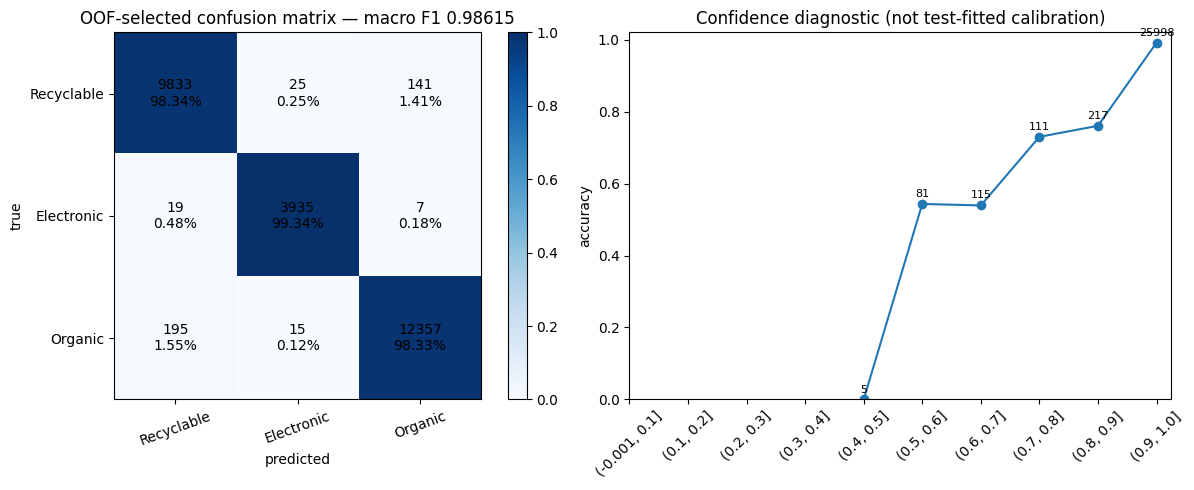

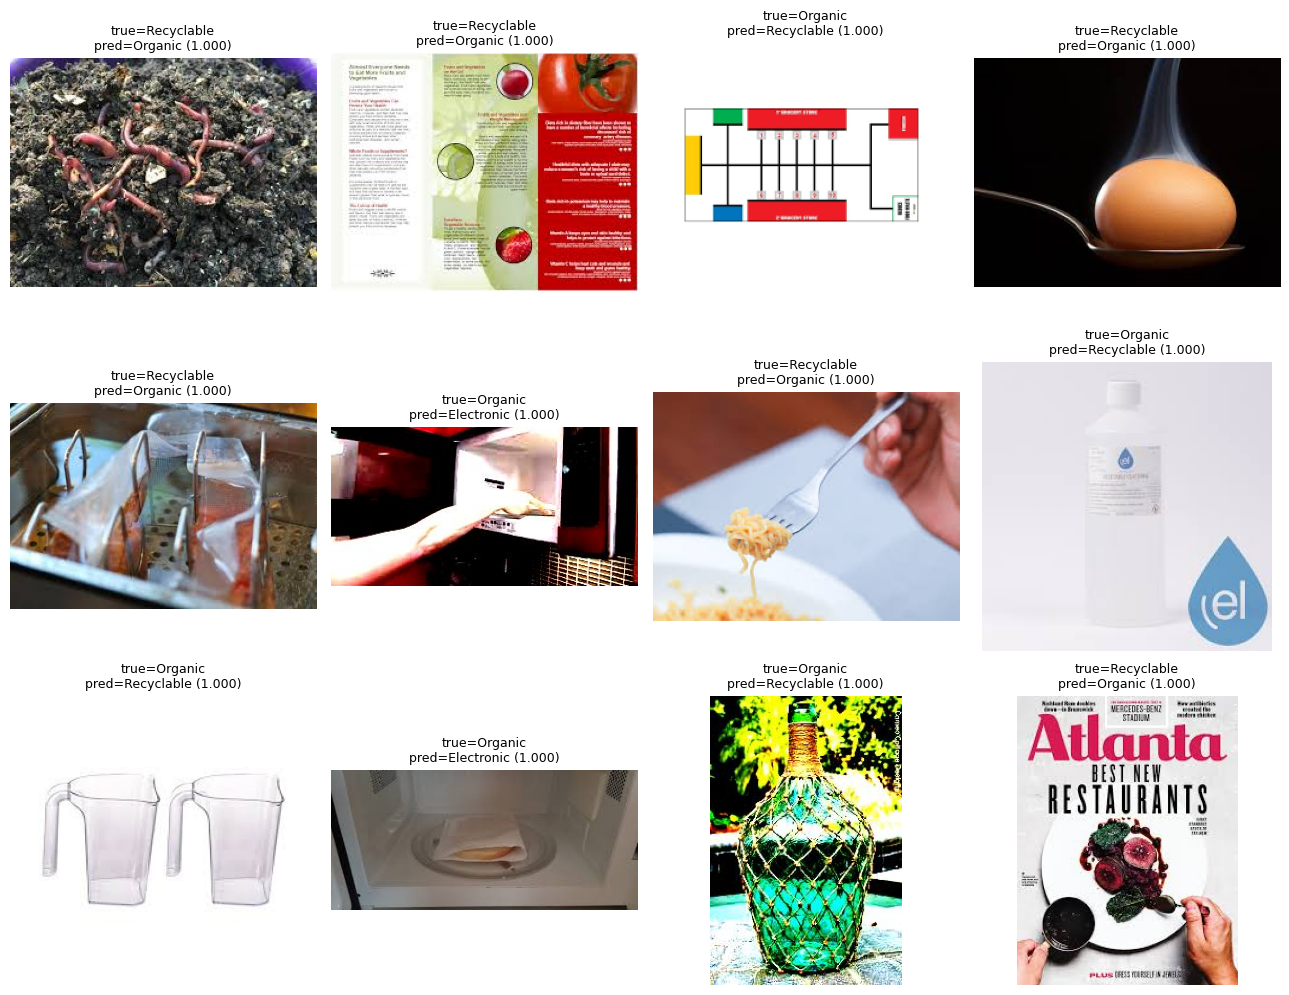

In [14]:
evaluated_frame = run_df.loc[evaluation_mask].copy().reset_index(drop=True)
oof_predictions = selected_oof_probabilities.argmax(axis=1).astype(np.int64)
oof_confidence = selected_oof_probabilities.max(axis=1)
sorted_oof_probabilities = np.sort(selected_oof_probabilities, axis=1)
oof_margin = sorted_oof_probabilities[:, -1] - sorted_oof_probabilities[:, -2]
selected_macro_f1 = f1_score(oof_labels, oof_predictions, average='macro')
oof_selected_macro_f1 = selected_macro_f1
selected_log_loss = log_loss(
    oof_labels, selected_oof_probabilities, labels=list(range(NUM_CLASSES))
)
report = classification_report(
    oof_labels,
    oof_predictions,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)
matrix = confusion_matrix(oof_labels, oof_predictions, labels=list(range(NUM_CLASSES)))

oof_table = evaluated_frame[['image_id', 'label', 'fold']].copy()
oof_table['prediction'] = oof_predictions
oof_table['confidence'] = oof_confidence
oof_table['margin'] = oof_margin
oof_table['correct'] = oof_predictions == oof_labels
oof_table['metric_role'] = 'oof_selected_selection_influenced'
for class_id in range(NUM_CLASSES):
    oof_table[f'prob_{class_id}'] = selected_oof_probabilities[:, class_id]
oof_table.to_csv(ARTIFACT_DIR / 'oof_predictions.csv', index=False)

orig_oof_predictions = orig_probabilities.argmax(axis=1).astype(np.int64)
per_fold_rows = []
for fold in sorted(oof_table['fold'].unique()):
    fold_mask = oof_table['fold'].to_numpy() == fold
    orig_role = (
        'recipe_selection_evidence' if int(fold) in RECIPE_SELECTION_FOLDS
        else 'assessment_original_view_not_used_for_recipe_selection'
    )
    per_fold_rows.append({
        'fold': int(fold),
        'rows': int(fold_mask.sum()),
        'orig_macro_f1': f1_score(
            oof_labels[fold_mask], orig_oof_predictions[fold_mask], average='macro'
        ),
        'orig_accuracy': float(
            (oof_labels[fold_mask] == orig_oof_predictions[fold_mask]).mean()
        ),
        'orig_metric_role': orig_role,
        'oof_selected_macro_f1': f1_score(
            oof_labels[fold_mask], oof_predictions[fold_mask], average='macro'
        ),
        'oof_selected_accuracy': float(
            (oof_labels[fold_mask] == oof_predictions[fold_mask]).mean()
        ),
        'oof_selected_metric_role': 'selection_influenced_by_all_active_fold_tta_choice',
    })
per_fold = pd.DataFrame(per_fold_rows)
per_fold.to_csv(ARTIFACT_DIR / 'per_fold_metrics.csv', index=False)
report_frame = pd.DataFrame(report).T
report_frame.to_csv(ARTIFACT_DIR / 'classification_report_oof_selected.csv')
prediction_distribution = pd.Series(oof_predictions).value_counts().sort_index().to_dict()
confidence_stats = {
    'mean': float(oof_confidence.mean()),
    'p05': float(np.quantile(oof_confidence, 0.05)),
    'minimum': float(oof_confidence.min()),
}
margin_stats = {
    'mean': float(oof_margin.mean()),
    'p05': float(np.quantile(oof_margin, 0.05)),
    'minimum': float(oof_margin.min()),
}
pairwise_confusions = {
    'recyclable_as_organic': int(matrix[0, 2]),
    'organic_as_recyclable': int(matrix[2, 0]),
}

metrics = {
    'run_mode': RUN_MODE,
    'debug_limit': DEBUG_LIMIT,
    'evaluated_rows': int(evaluation_mask.sum()),
    'selected_recipe': selected_recipe,
    'selected_views': list(selected_views),
    'selection_fold_orig_macro_f1': selection_fold_orig_macro_f1,
    'assessment_folds': list(ASSESSMENT_FOLDS),
    'assessment_orig_macro_f1': assessment_orig_macro_f1,
    'all_active_folds_orig_macro_f1_selection_influenced': orig_f1,
    'oof_selected_macro_f1_selection_influenced': oof_selected_macro_f1,
    'oof_selected_metric_is_unbiased': False,
    'oof_selected_log_loss_selection_influenced': selected_log_loss,
    'all_active_folds_orig_plus_hflip_macro_f1_oof_selected': two_view_f1,
    'classification_report_oof_selected_selection_influenced': report,
    'confusion_matrix_oof_selected_selection_influenced': matrix,
    'prediction_distribution_oof_selected_selection_influenced': prediction_distribution,
    'confidence_summary': confidence_stats,
    'margin_summary': margin_stats,
    'pairwise_confusions': pairwise_confusions,
    'oof_selected_fold_macro_f1_mean_selection_influenced': float(
        per_fold['oof_selected_macro_f1'].mean()
    ),
    'oof_selected_fold_macro_f1_std_selection_influenced': float(
        per_fold['oof_selected_macro_f1'].std(ddof=0)
    ),
    'per_fold': per_fold.to_dict(orient='records'),
}
write_json_atomic(metrics, ARTIFACT_DIR / 'oof_metrics.json')
display(per_fold)
display(report_frame)
print(
    'OOF-selected/selection-influenced fold macro-F1 mean/std: '
    f"{metrics['oof_selected_fold_macro_f1_mean_selection_influenced']:.6f} / "
    f"{metrics['oof_selected_fold_macro_f1_std_selection_influenced']:.6f}"
)
print('OOF prediction distribution:', prediction_distribution)
print('Recyclable↔Organic confusions:', pairwise_confusions)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
row_sums = matrix.sum(axis=1, keepdims=True)
normalized_matrix = np.divide(matrix, row_sums, where=row_sums != 0)
image = axes[0].imshow(normalized_matrix, cmap='Blues', vmin=0, vmax=1)
for row in range(NUM_CLASSES):
    for column in range(NUM_CLASSES):
        axes[0].text(column, row, f'{matrix[row, column]}\n{normalized_matrix[row, column]:.2%}',
                     ha='center', va='center', color='black')
axes[0].set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=20)
axes[0].set_yticks(range(NUM_CLASSES), CLASS_NAMES)
axes[0].set_xlabel('predicted')
axes[0].set_ylabel('true')
axes[0].set_title(f'OOF-selected confusion matrix — macro F1 {oof_selected_macro_f1:.5f}')
fig.colorbar(image, ax=axes[0], fraction=0.046)

confidence_bins = pd.cut(oof_table['confidence'], bins=np.linspace(0, 1, 11), include_lowest=True)
confidence_summary = oof_table.groupby(confidence_bins, observed=False).agg(
    accuracy=('correct', 'mean'), rows=('correct', 'size')
).reset_index()
axes[1].plot(range(len(confidence_summary)), confidence_summary['accuracy'], marker='o')
axes[1].set_xticks(range(len(confidence_summary)), confidence_summary['confidence'].astype(str), rotation=45)
axes[1].set_ylim(0, 1.02)
axes[1].set_ylabel('accuracy')
axes[1].set_title('Confidence diagnostic (not test-fitted calibration)')
for index, row in confidence_summary.iterrows():
    if np.isfinite(row['accuracy']):
        axes[1].annotate(str(int(row['rows'])), (index, row['accuracy']), xytext=(0, 5),
                         textcoords='offset points', ha='center', fontsize=8)
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / 'oof_diagnostics.png', dpi=170, bbox_inches='tight')
plt.show()

error_table = oof_table.loc[~oof_table['correct']].sort_values('confidence', ascending=False)
error_table.head(100).to_csv(ARTIFACT_DIR / 'high_confidence_errors.csv', index=False)
if len(error_table):
    shown = error_table.head(12)
    fig, axes = plt.subplots(3, 4, figsize=(13, 10))
    for axis in axes.flat:
        axis.axis('off')
    path_lookup = run_df.set_index('image_id')['path']
    for axis, row in zip(axes.flat, shown.itertuples(index=False)):
        axis.imshow(load_rgb_image(path_lookup.loc[row.image_id]))
        axis.set_title(
            f'true={CLASS_NAMES[row.label]}\npred={CLASS_NAMES[row.prediction]} ({row.confidence:.3f})',
            fontsize=9,
        )
        axis.axis('off')
    plt.tight_layout()
    plt.savefig(ARTIFACT_DIR / 'oof_error_examples.png', dpi=150, bbox_inches='tight')
    plt.show()


## Inference final — akses test baru dimulai di sini

Cell berikut inert pada mode screen/debug. Pada run full yang bersih, barulah template dibaca dan citra test dienumerasi sesuai urutan template. View deterministik yang sudah dipilih diekstrak memakai backbone frozen yang masih sama; tepat 10 checkpoint probe dimuat, logit fold/seed dirata-ratakan, lalu probabilitas antar-view terpilih dirata-ratakan.

In [15]:
if not FULL_RUN:
    print('SCREEN MODE COMPLETE — train-only artifacts written; test was not enumerated and no submission was created.')

if FULL_RUN:
    submission_template = pd.read_csv(TEMPLATE_PATH, dtype={'id': 'string'})
    if submission_template.columns.tolist() != ['id', 'predicted']:
        raise RuntimeError(
            f'Expected template columns ["id", "predicted"], got {submission_template.columns.tolist()}.'
        )
    if len(submission_template) != EXPECTED_TEST_ROWS:
        raise RuntimeError(
            f'Expected {EXPECTED_TEST_ROWS} template rows, got {len(submission_template)}.'
        )
    if submission_template['id'].isna().any() or not submission_template['id'].is_unique:
        raise RuntimeError('Template IDs must be non-null and unique.')

    test_entries = sorted(TEST_DIR.iterdir(), key=lambda path: path.name)
    invalid_test_entries = [
        path.name for path in test_entries
        if not path.is_file() or path.suffix.lower() not in ALLOWED_IMAGE_SUFFIXES
    ]
    if invalid_test_entries:
        raise RuntimeError(f'Unsupported or nested test entries: {invalid_test_entries[:10]}')
    if len(test_entries) != EXPECTED_TEST_ROWS:
        raise RuntimeError(f'Expected {EXPECTED_TEST_ROWS} test images, got {len(test_entries)}.')

    test_lookup = {}
    for path in test_entries:
        for key in (path.name, path.stem):
            if key in test_lookup and test_lookup[key] != path:
                raise RuntimeError(f'Ambiguous test identifier: {key}')
            test_lookup[key] = path

    ordered_test_paths = []
    ordered_test_ids = submission_template['id'].astype(str).tolist()
    for template_id in ordered_test_ids:
        candidate_keys = (template_id, Path(template_id).name, Path(template_id).stem)
        matches = {test_lookup[key] for key in candidate_keys if key in test_lookup}
        if len(matches) != 1:
            raise RuntimeError(f'Template ID {template_id!r} matched {len(matches)} test files.')
        ordered_test_paths.append(str(matches.pop()))
    if len(set(ordered_test_paths)) != EXPECTED_TEST_ROWS:
        raise RuntimeError('Template ordering did not map one-to-one onto test images.')

    test_df = pd.DataFrame({
        'image_id': ordered_test_ids,
        'relative_path': [Path(path).name for path in ordered_test_paths],
        'path': ordered_test_paths,
    })
    test_df = prepare_safe_image_paths(test_df, split='test')
    test_feature_caches = extract_or_load_feature_shards(
        test_df,
        split='test',
        views=selected_views,
        selected_view_policy=selected_views,
    )
    if tuple(test_feature_caches) != tuple(selected_views):
        raise RuntimeError('Test cache views tidak persis mengikuti selected OOF view policy.')
    for view in selected_views:
        metadata = test_feature_caches[view]['metadata']
        if metadata['ordered_image_ids'] != ordered_test_ids:
            raise RuntimeError(f'Urutan test shard berubah untuk view {view}.')
        if metadata['selected_view_policy'] != list(selected_views):
            raise RuntimeError(f'View policy test shard tidak cocok untuk view {view}.')
        if metadata['preprocess_signature'] != PREPROCESS_SIGNATURE:
            raise RuntimeError(f'Preprocessing test shard tidak cocok untuk view {view}.')
    print('Test features extracted only for the train-OOF-selected views.')


image safety test:   0%|          | 0/1458 [00:00<?, ?it/s]

Image safety test: 19 large, 19 dibuat, 0 dipakai ulang. Dimensi tidak digunakan sebagai fitur.


test/orig shard 000:   0%|          | 0/128 [00:00<?, ?it/s]

test/orig shard 001:   0%|          | 0/128 [00:00<?, ?it/s]

test/orig shard 002:   0%|          | 0/109 [00:00<?, ?it/s]

test/orig: 0 shard reused, 3 shard extracted.
Test features extracted only for the train-OOF-selected views.


In [16]:
if FULL_RUN:
    test_representations = make_representations(test_feature_caches, selected_recipe['pooling'])

    # The backbone was loaded once and is released only after all train/test feature caches exist.
    del feature_model, pooler, backbone
    gc.collect()
    torch.cuda.empty_cache()

    discovered = {
        path.relative_to(head_dir).as_posix(): path
        for path in head_dir.rglob('head_*.pt')
    }
    if set(discovered) != expected_checkpoint_names:
        raise RuntimeError('Final inference checkpoint set differs from the validated OOF set.')

    test_logit_sums = {
        view: np.zeros((EXPECTED_TEST_ROWS, NUM_CLASSES), dtype=np.float64)
        for view in selected_views
    }
    checkpoint_count = 0
    for fold in active_folds:
        for seed in head_seeds:
            name = f'head_{selected_recipe["name"]}_fold{fold}_seed{seed}.pt'
            checkpoint = torch.load(discovered[name], map_location='cpu', weights_only=False)
            expected_metadata = checkpoint_metadata(
                selected_recipe, fold, seed, test_representations['orig'].shape[1]
            )
            if checkpoint.get('metadata') != expected_metadata:
                raise RuntimeError(f'Checkpoint metadata mismatch: {name}')
            probe = Probe(expected_metadata['input_dim'], selected_recipe['head']).to('cuda:0')
            probe.load_state_dict(checkpoint['state_dict'], strict=True)
            for view in selected_views:
                test_logit_sums[view] += predict_probe(probe, test_representations[view])
            checkpoint_count += 1
            del probe, checkpoint
            torch.cuda.empty_cache()

    if checkpoint_count != len(expected_checkpoint_names):
        raise RuntimeError('Final ensemble used the wrong number of checkpoints.')
    test_probabilities_by_view = {
        view: softmax_numpy(logits / checkpoint_count)
        for view, logits in test_logit_sums.items()
    }
    test_probabilities = np.mean(list(test_probabilities_by_view.values()), axis=0)
    if test_probabilities.shape != (EXPECTED_TEST_ROWS, NUM_CLASSES):
        raise RuntimeError(f'Unexpected test probability shape: {test_probabilities.shape}')
    if not np.isfinite(test_probabilities).all():
        raise RuntimeError('Test probabilities contain non-finite values.')
    test_predictions = test_probabilities.argmax(axis=1).astype(np.int64)
    if not set(np.unique(test_predictions)).issubset(set(range(NUM_CLASSES))):
        raise RuntimeError('Predictions contain labels outside {0,1,2}.')

    prediction_audit = pd.DataFrame({'id': ordered_test_ids, 'prediction': test_predictions})
    for class_id in range(NUM_CLASSES):
        prediction_audit[f'prob_{class_id}'] = test_probabilities[:, class_id]
    prediction_audit.to_csv(ARTIFACT_DIR / 'test_prediction_audit.csv', index=False)


In [17]:
if FULL_RUN:
    submission = submission_template.copy()
    submission['predicted'] = test_predictions
    if submission.columns.tolist() != submission_template.columns.tolist():
        raise RuntimeError('Submission columns or order changed from the official template.')
    if len(submission) != EXPECTED_TEST_ROWS:
        raise RuntimeError('Submission row count changed from the official template.')
    if submission['id'].astype(str).tolist() != submission_template['id'].astype(str).tolist():
        raise RuntimeError('Submission ID values or order changed from the official template.')
    if not submission['id'].is_unique:
        raise RuntimeError('Submission IDs must remain unique.')
    if submission['predicted'].isna().any() or not pd.api.types.is_integer_dtype(submission['predicted']):
        raise RuntimeError('Submission predictions must be non-null integers.')
    if not set(submission['predicted'].unique()).issubset(set(range(NUM_CLASSES))):
        raise RuntimeError('Submission predictions must be in {0,1,2}.')

    submission_path = KAGGLE_WORKING / 'submission_SD2026040000412.csv'
    temporary_submission = submission_path.with_name(submission_path.name + '.tmp')
    submission.to_csv(temporary_submission, index=False)
    os.replace(temporary_submission, submission_path)

    round_trip = pd.read_csv(submission_path, dtype={'id': 'string'})
    if round_trip.columns.tolist() != ['id', 'predicted'] or len(round_trip) != EXPECTED_TEST_ROWS:
        raise RuntimeError('Written submission failed the round-trip schema check.')
    if round_trip['id'].astype(str).tolist() != submission_template['id'].astype(str).tolist():
        raise RuntimeError('Written submission failed the round-trip ID order check.')
    if round_trip['predicted'].astype(int).tolist() != test_predictions.tolist():
        raise RuntimeError('Written submission failed the round-trip prediction check.')

    manifest = {
        'submission_path': str(submission_path),
        'team_id': 'SD2026040000412',
        'data_root': str(DATA_ROOT),
        'raw_class_counts': EXPECTED_RAW_COUNTS,
        'train_rows': EXPECTED_TRAIN_ROWS,
        'test_rows': EXPECTED_TEST_ROWS,
        'model_id': MODEL_ID,
        'model_revision': RESOLVED_REVISION,
        'backbone_compute_dtype': BACKBONE_COMPUTE_DTYPE_NAME,
        'feature_storage_dtype': FEATURE_STORAGE_DTYPE_NAME,
        'attention_implementation': ATTENTION_IMPLEMENTATION,
        'image_size': IMAGE_SIZE,
        'backbone_trainable_parameters': 0,
        'selected_recipe': selected_recipe,
        'selected_views': list(selected_views),
        'view_selection_source': 'train_oof_only',
        'folds': list(active_folds),
        'head_seeds': list(head_seeds),
        'checkpoint_names': sorted(expected_checkpoint_names),
        'processor_config': PREPROCESS_CONFIG,
        'preprocess_signature': PREPROCESS_SIGNATURE,
        'selection_fold_orig_macro_f1': selection_fold_orig_macro_f1,
        'assessment_folds': list(ASSESSMENT_FOLDS),
        'assessment_orig_macro_f1': assessment_orig_macro_f1,
        'oof_selected_macro_f1_selection_influenced': selected_macro_f1,
        'oof_selected_log_loss_selection_influenced': selected_log_loss,
        'prediction_counts': pd.Series(test_predictions).value_counts().sort_index().to_dict(),
        'automatic_upload': False,
    }
    write_json_atomic(manifest, ARTIFACT_DIR / 'run_manifest.json')
    print('\nSubmission ready:', submission_path)
    print('Prediction counts:', manifest['prediction_counts'])
    print('Post-inference sanity report only: do not use prediction counts to retune the model.')
    print('No upload was attempted; preserve the remaining submission budget for reviewed candidates.')
    display(submission.head())



Submission ready: /kaggle/working/submission_SD2026040000412.csv
Prediction counts: {0: 521, 1: 199, 2: 738}
Post-inference sanity report only: do not use prediction counts to retune the model.
No upload was attempted; preserve the remaining submission budget for reviewed candidates.


,id,predicted
0,1,2
1,2,2
2,3,2
3,4,1
4,5,0


## Interpretasi dan checklist anggaran submission

Sebelum memakai slot leaderboard, periksa `probe_screen_selection_evidence.csv`, metrik assessment original-view folds 1–4 di `oof_metrics.json`, metrik aggregate yang berlabel OOF-selected/selection-influenced, confusion matrix ternormalisasi, variasi antar-fold, bin confidence, margin, dan contoh error ber-confidence tinggi. Peningkatan terhadap v3 harus bermakna, bukan artefak pembulatan; semua kelas harus kuat pada macro-F1 dan tidak boleh ada satu fold yang collapse. Notebook membuat—tetapi tidak mengunggah—submission sehingga review ini dapat dilakukan lebih dulu.

Failure mode dibuat eksplisit: dataset relabel memicu assertion raw count; file rusak/tidak dikenal menghentikan ekstraksi; perubahan Hub revision menghasilkan kontrak cache berbeda; cache/checkpoint stale atau parsial ditolak; GPU yang kurang menghentikan mode full; dan mismatch template, urutan ID, jumlah baris, domain label, dtype, atau round-trip CSV mencegah handoff. Distribusi prediksi test hanyalah sanity report pasca-inference dan tidak boleh dipakai untuk retuning.